# Surrogate diagnostics: run 4 results overview

Run all cells using the Python kernel from **ligoopt** to refresh this report
from saved files in `analysis/surrogate_diagnostics/outputs/`. Open the notebook
from the repository root or this directory. Refreshing reads CSV/JSON artifacts
and does not train models or launch Finesse simulations.

This report covers data and inference-feature audits, the matched initial
designs and held-out validation, original production training, online PSO
behavior, checkpoint replay, five-group reconstruction and transfer, signed
perturbation responses, and source provenance.

Run 4 production uses `nominal_delta`, combining nominal log-power and signed
power-difference terms. The diagnostic `paired` tiny-fit experiment retains
the older row log-power plus difference objective. Tiny-fit scores measure
training reconstruction; feedback checkpoint replay includes prior online
training exposure and does not establish held-out generalization.

Only run 4 artifact folders are included. Run 3 checkpoints remain reference
baselines within matched run 4 comparisons. Open the [run 3 notebook](results_overview_run3.ipynb)
for the earlier analysis, or the [run 4 findings overview](RUN4_FINDINGS.html)
for the concise report. Figures can optionally be exported as PNG files.


In [1]:
import csv
import html
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
import numpy as np
from IPython.display import HTML, Image, Markdown, display

REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'analysis/surrogate_diagnostics').is_dir() and (p / 'MLP').is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook with a working directory inside ligo-opt.')
DIAGNOSTICS_DIR = REPO_ROOT / 'analysis/surrogate_diagnostics'
OUTPUTS_DIR = DIAGNOSTICS_DIR / 'outputs'

RUN_NUMBER = 4
# None includes every saved experiment for this run. Example: {'run4_five_groups_fresh', 'run4_five_groups_warm'}.
EXPERIMENT_FILTER = None
INCLUDE_SMOKE = True
DELTA_ERROR_TARGET_W = 0.1
TOP_ERRORS_PER_RUN_SPLIT = 3
EXPORT_FIGURES = False
EXPORT_DIR = OUTPUTS_DIR / f'notebook_figures_run{RUN_NUMBER}'

# Change these and rerun the group-response cell to inspect any saved feedback group.
DETAIL_EXPERIMENT = 'run4_comparison'
DETAIL_SPLIT = 'feedback'
DETAIL_GROUP = 'round:40:0'
SHOW_ALL_GROUP_RESPONSES = False
SHOW_SAVED_FIGURES = False

DIRECTIONS = ['nominal', 'ITM_plus', 'ITM_minus', 'ETM_plus', 'ETM_minus', 'joint']
SPLITS = ['train', 'validation', 'test', 'all']
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 140, 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.2, 'axes.spines.top': False,
    'axes.spines.right': False,
})
print(f'Reading: {OUTPUTS_DIR}')


Reading: /home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs


## Load and inspect the saved artifacts

Every run 4 `audit.json` and `metrics.json` is included. Metrics are read directly so that
standalone checkpoint evaluations, which have no `summary.csv`, are included too.
Tables use expandable panels for complete sample-level results.


In [2]:
def read_json(path):
    return json.loads(path.read_text()) if path.exists() else {}


def read_csv(path):
    if not path.exists():
        return []
    def convert(value):
        if value == '':
            return None
        if value in ('True', 'False'):
            return value == 'True'
        try:
            return int(value)
        except ValueError:
            try:
                return float(value)
            except ValueError:
                return value
    with path.open(newline='') as stream:
        return [{k: convert(v) for k, v in row.items()} for row in csv.DictReader(stream)]


def formatted(value):
    if value is None:
        return '—'
    if isinstance(value, (float, np.floating)):
        return f'{value:.6g}'
    return str(value)


def table(rows, columns=None, title=None, collapsed=False):
    if not rows:
        display(Markdown(f'**{title or "Table"}:** no saved rows.'))
        return
    columns = columns or list(dict.fromkeys(k for row in rows for k in row))
    header = ''.join(f'<th>{html.escape(k)}</th>' for k in columns)
    body = ''.join('<tr>' + ''.join(
        f'<td>{html.escape(formatted(row.get(k)))}</td>' for k in columns
    ) + '</tr>' for row in rows)
    content = (
        '<div style="max-height:480px;overflow:auto">'
        '<table style="border-collapse:collapse;text-align:left;font-size:12px">'
        f'<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'
    )
    caption = html.escape(f'{title or "Rows"} ({len(rows)} rows)')
    if collapsed:
        content = f'<details><summary>{caption}</summary>{content}</details>'
    else:
        content = f'<p><b>{caption}</b></p>{content}'
    display(HTML(content))


def json_panel(title, value):
    text = html.escape(json.dumps(value, indent=2))
    display(HTML(f'<details><summary>{html.escape(title)}</summary>'
                 f'<pre style="max-height:450px;overflow:auto">{text}</pre></details>'))


figure_count = 0
def show_figure(fig, name):
    global figure_count
    figure_count += 1
    if EXPORT_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        safe_name = ''.join(c if c.isalnum() or c in '-_' else '_' for c in name)
        fig.savefig(EXPORT_DIR / f'{safe_name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def values(rows, field):
    return np.array([r[field] if r.get(field) is not None else np.nan for r in rows], dtype=float)


def parity_line(ax, x, y):
    both = np.concatenate([np.asarray(x), np.asarray(y)])
    both = both[np.isfinite(both)]
    if not len(both):
        return
    lo, hi = both.min(), both.max()
    pad = max((hi - lo) * 0.05, abs(hi) * 0.02, 1e-6)
    limits = (lo - pad, hi + pad)
    ax.plot(limits, limits, '--', color='black', lw=1, label='Exact agreement')
    ax.set_xlim(limits)
    ax.set_ylim(limits)


def artifact_run(name):
    # The parent experiment owns cross-run comparisons, including reference checkpoints.
    directory = OUTPUTS_DIR / name.split('/')[0]
    config = read_json(directory / 'config.json')
    if config.get('target_run') is not None:
        return int(config['target_run'])
    data_name = Path(config.get('data_dir') or '').name
    if data_name.startswith('run') and data_name[3:].isdigit():
        return int(data_name[3:])
    # Training audits have no config.json; named run folders retain automatic discovery.
    folder_run = directory.name.split('_')[0]
    if folder_run.startswith('run') and folder_run[3:].isdigit():
        return int(folder_run[3:])
    return None


def included(name):
    return artifact_run(name) == RUN_NUMBER and (
        EXPERIMENT_FILTER is None or name in EXPERIMENT_FILTER
    ) and (INCLUDE_SMOKE or 'smoke' not in name.lower())


audits, runs, experiments = {}, {}, {}
predictions_rows, metric_rows, direction_rows, cost_rows, history_rows = [], [], [], [], []
for path in sorted(OUTPUTS_DIR.rglob('audit.json')):
    name = path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if included(name):
        audits[name] = {'path': path.parent, 'audit': read_json(path),
                        'config': read_json(path.parent / 'config.json'),
                        'samples': read_csv(path.parent / 'samples.csv'),
                        'features': read_csv(path.parent / 'inference_features.csv')}

for path in sorted(OUTPUTS_DIR.rglob('metrics.json')):
    directory = path.parent
    experiment_dir = directory
    for parent in (directory, *directory.parents):
        if parent == OUTPUTS_DIR:
            break
        if (parent / 'summary.csv').exists() or (parent / 'provenance.json').exists():
            experiment_dir = parent
            break
    experiment = experiment_dir.relative_to(OUTPUTS_DIR).as_posix()
    if not included(experiment):
        continue
    run_id = directory.relative_to(OUTPUTS_DIR).as_posix()
    config = read_json(directory / 'config.json')
    metrics = read_json(path)
    # Preserve each production checkpoint's saved initial split metadata
    # in a separate experiment, even when initial designs are matched.
    if metrics.get('checkpoint_training_metadata') and 'feedback' not in metrics.get('splits', {}):
        experiment_dir = directory
        experiment = run_id
    scope = ('standalone checkpoint evaluation' if metrics.get('checkpoint') else
             'generalization smoke run' if 'smoke' in experiment.lower() else
             'training-set fit' if metrics.get('mode', config.get('mode')) == 'tiny_fit' else
             'grouped generalization')
    tags = {'experiment': experiment, 'run_id': run_id,
            'variant': config.get('variant', 'checkpoint'), 'seed': config.get('seed'),
            'detector': config.get('detector'), 'scope': scope}
    current_predictions = [{**row, **tags} for row in read_csv(directory / 'predictions.csv')]
    current_history = [{**row, **tags} for row in read_csv(directory / 'training_history.csv')]
    runs[run_id] = {'path': directory, 'config': config, 'metrics': metrics, 'tags': tags,
                    'predictions': current_predictions, 'history': current_history}
    experiments[experiment] = {'path': experiment_dir,
                               'config': read_json(experiment_dir / 'config.json'),
                               'provenance': read_json(experiment_dir / 'provenance.json'),
                               'scope': scope}
    predictions_rows.extend(current_predictions)
    history_rows.extend(current_history)
    for split, result in metrics.get('splits', {}).items():
        metric_rows.append({**tags, 'split': split, 'best_epoch': metrics.get('best_epoch'),
                            'monitor_split': metrics.get('monitor_split'),
                            **{k: v for k, v in result.items() if k != 'by_direction'}})
        for direction, stats in result.get('by_direction', {}).items():
            direction_rows.append({**tags, 'split': split, 'direction': direction, **stats})
    for split, costs in read_json(directory / 'costs.json').items():
        for row in costs:
            valid = row.get('true_perturbation_cost') is not None and row.get('predicted_perturbation_cost') is not None
            cost_rows.append({**tags, 'split': split, **row,
                              'cost_error': row['predicted_perturbation_cost'] - row['true_perturbation_cost'] if valid else None})

if not audits and not runs:
    display(Markdown('No saved diagnostic outputs match the current filters. '
                     'Run an audit/evaluation using the commands in README.md, then refresh this notebook.'))
print(f'{len(audits)} audits; {len(experiments)} evaluation/fit experiments; '
      f'{len(runs)} checkpoints; {len(metric_rows)} run/split metric rows; '
      f'{len(predictions_rows)} predictions.')


2 audits; 7 evaluation/fit experiments; 14 checkpoints; 20 run/split metric rows; 3080 predictions.


In [3]:
inventory = []
for name, record in sorted({**audits, **experiments}.items()):
    paths = [p for p in record['path'].rglob('*') if p.is_file()]
    inventory.append({
        'folder': name, 'scope': 'data / feature audit' if name in audits else record['scope'],
        'files': len(paths), 'CSV': sum(p.suffix == '.csv' for p in paths),
        'JSON': sum(p.suffix == '.json' for p in paths),
        'PNG': sum(p.suffix == '.png' for p in paths),
        'checkpoints': sum(p.suffix == '.pt' for p in paths),
    })
table(inventory, title='Saved output folders')
artifact_rows = [{'path': p.relative_to(DIAGNOSTICS_DIR).as_posix(),
                  'bytes': p.stat().st_size}
                 for p in sorted(OUTPUTS_DIR.rglob('*'))
                 if p.is_file() and included(p.relative_to(OUTPUTS_DIR).parts[0])]
table(artifact_rows, title='Complete artifact inventory', collapsed=True)


folder,scope,files,CSV,JSON,PNG,checkpoints
run4_audit,data / feature audit,3,1,2,0,0
run4_comparison,standalone checkpoint evaluation,34,10,21,3,0
run4_comparison/run3_base_on_initial,standalone checkpoint evaluation,4,1,3,0,0
run4_comparison/run4_base_on_initial,standalone checkpoint evaluation,4,1,3,0,0
run4_five_groups_fresh,training-set fit,21,7,11,0,3
run4_five_groups_warm,training-set fit,21,7,11,0,3
run4_selected_feature_audit,data / feature audit,4,2,2,0,0
run4_transfer_center_focused,standalone checkpoint evaluation,4,1,3,0,0
run4_transfer_paired,standalone checkpoint evaluation,4,1,3,0,0


path,bytes
outputs/run4_audit/audit.json,6151
outputs/run4_audit/config.json,1127
outputs/run4_audit/samples.csv,156716
outputs/run4_comparison/comparison.json,75868
outputs/run4_comparison/config.json,388
outputs/run4_comparison/final_response_shape.json,297
outputs/run4_comparison/online_cost_and_power.png,271506
outputs/run4_comparison/online_roc_coverage.png,122593
outputs/run4_comparison/online_rounds.csv,47952
outputs/run4_comparison/online_samples.csv,157512


## Data coverage and label audit

The audits include invalid fixed-q groups and zero-output rows. A zero label
alone cannot distinguish an unstable cavity from a solver or lock failure.
Runs 3 and 4 share initial geometric designs, each recorded as five-row
nominal/ITM+/ITM-/ETM+/ETM- groups. Their online feedback visits different
designs. The center band comes from each saved config.

All ROC sample-coverage panels use the full `run4_audit` ITM/ETM axis ranges.
Nominal q coverage panels likewise share its nominal Re(q)/Im(q) axis ranges,
so selected feedback designs can be compared with the complete coverage.


audit,groups,rows,valid_fixed_q_groups,zero_output_rows,center_rows,invalid_fixed_q_groups,power_range_W,delta_range_W,feature_check_rows,feature_mismatches,detector
run4_audit,140,700,118,104,231,22,"[0.0, 282.09411094292744]","[-60.88990203739854, 66.96801039125108]",—,—,p_ITM_p2_i
run4_selected_feature_audit,5,25,5,0,1,0,"[281.5697439223032, 282.08072109403827]","[-0.27091763985265516, 0.030069723371298096]",25,0,p_ITM_p2_i


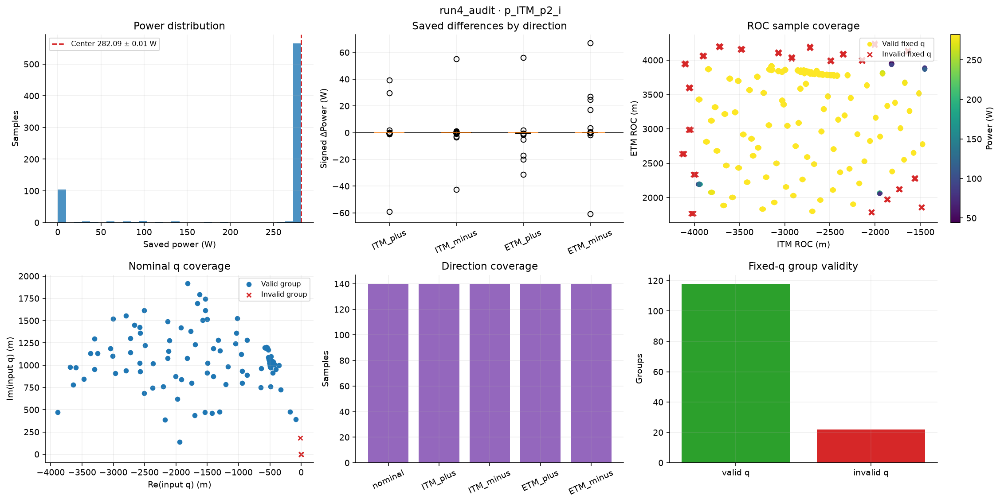

feature,minimum,maximum,std
ITM ROC (m),-4138.77,-1447.08,669.55
ETM ROC (m),1761.14,4247.48,714.209
Re(q) (m),-3973.03,0,1066.37
Im(q) (m),0,1918.67,469.257


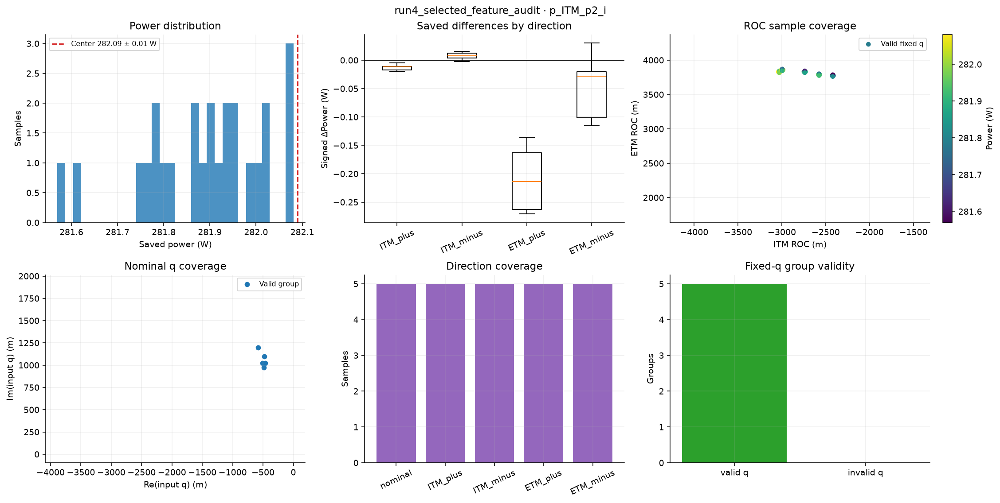

feature,minimum,maximum,std
ITM ROC (m),-3039.68,-2410.84,236.187
ETM ROC (m),3762.06,3870.37,31.3219
Re(q) (m),-584.268,-461.778,42.3448
Im(q) (m),971.662,1195.31,77.7082


In [4]:
audit_rows = []
for name, record in audits.items():
    audit = record['audit']
    check = audit.get('inference_check') or {}
    audit_rows.append({
        'audit': name, **{k: audit.get(k) for k in
            ('groups', 'rows', 'valid_fixed_q_groups', 'zero_output_rows', 'center_rows')},
        'invalid_fixed_q_groups': audit.get('groups', 0) - audit.get('valid_fixed_q_groups', 0),
        'power_range_W': audit.get('power_range_w'),
        'delta_range_W': audit.get('delta_range_w'),
        'feature_check_rows': check.get('rows'), 'feature_mismatches': check.get('mismatches'),
        'detector': record['config'].get('detector'),
    })
table(audit_rows, title='Audit totals (each audit is a separate sample selection)')

# Use the full audit's coverage extents even when only a selected audit is displayed.
coverage_reference_rows = read_csv(OUTPUTS_DIR / f'run{RUN_NUMBER}_audit' / 'samples.csv')
if not coverage_reference_rows:
    coverage_reference_rows = [row for record in audits.values() for row in record['samples']]


def coverage_axis_limits(rows, features):
    limits = {}
    for feature in features:
        coordinates = values(rows, feature)
        coordinates = coordinates[np.isfinite(coordinates)]
        if coordinates.size:
            lo, hi = coordinates.min(), coordinates.max()
            padding = 0.05 * max(hi - lo, 1.0)
            limits[feature] = (lo - padding, hi + padding)
    return limits


roc_limits = coverage_axis_limits(coverage_reference_rows, ('ITM_Rc', 'ETM_Rc'))
nominal_reference_rows = [row for row in coverage_reference_rows if row['direction'] == 'nominal']
nominal_q_limits = coverage_axis_limits(nominal_reference_rows, ('q_input_real', 'q_input_imag'))

for name, record in audits.items():
    rows, audit = record['samples'], record['audit']
    if not rows:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    axes[0, 0].hist(values(rows, 'power'), bins=30, color='tab:blue', alpha=0.8)
    center = record['config'].get('center_loss', {})
    if center:
        axes[0, 0].axvline(center['center_power'], color='tab:red', ls='--',
                          label=f"Center {center['center_power']} ± {center['center_width']} W")
        axes[0, 0].legend(fontsize=8)
    axes[0, 0].set(xlabel='Saved power (W)', ylabel='Samples', title='Power distribution')
    directions = [d for d in DIRECTIONS if d != 'nominal' and any(r['direction'] == d for r in rows)]
    if directions:
        axes[0, 1].boxplot([values([r for r in rows if r['direction'] == d], 'delta_power') for d in directions])
        axes[0, 1].set_xticks(range(1, len(directions) + 1), directions, rotation=25)
    axes[0, 1].axhline(0, color='black', lw=1)
    axes[0, 1].set(ylabel='Signed ΔPower (W)', title='Saved differences by direction')
    valid = [r for r in rows if r.get('valid_fixed_q_group')]
    invalid = [r for r in rows if not r.get('valid_fixed_q_group')]
    scatter = axes[0, 2].scatter(values(valid, 'ITM_Rc'), values(valid, 'ETM_Rc'),
                                c=values(valid, 'power'), s=20, cmap='viridis', label='Valid fixed q')
    if invalid:
        axes[0, 2].scatter(values(invalid, 'ITM_Rc'), values(invalid, 'ETM_Rc'),
                           marker='x', color='tab:red', s=30, label='Invalid fixed q')
    fig.colorbar(scatter, ax=axes[0, 2], label='Power (W)')
    axes[0, 2].set(xlabel='ITM ROC (m)', ylabel='ETM ROC (m)', title='ROC sample coverage',
                   xlim=roc_limits.get('ITM_Rc'), ylim=roc_limits.get('ETM_Rc'))
    axes[0, 2].legend(fontsize=8)
    nominal = [r for r in rows if r['direction'] == 'nominal']
    for status, marker, color in ((True, 'o', 'tab:blue'), (False, 'x', 'tab:red')):
        subset = [r for r in nominal if bool(r.get('valid_fixed_q_group')) == status]
        if subset:
            axes[1, 0].scatter(values(subset, 'q_input_real'), values(subset, 'q_input_imag'),
                               marker=marker, color=color, s=25,
                               label='Valid group' if status else 'Invalid group')
    axes[1, 0].set(xlabel='Re(input q) (m)', ylabel='Im(input q) (m)', title='Nominal q coverage',
                   xlim=nominal_q_limits.get('q_input_real'), ylim=nominal_q_limits.get('q_input_imag'))
    axes[1, 0].legend(fontsize=8)
    counts = Counter(r['direction'] for r in rows)
    present = [d for d in DIRECTIONS if d in counts]
    axes[1, 1].bar(present, [counts[d] for d in present], color='tab:purple')
    axes[1, 1].tick_params(axis='x', rotation=25)
    axes[1, 1].set(ylabel='Samples', title='Direction coverage')
    axes[1, 2].bar(['valid q', 'invalid q'],
                   [audit['valid_fixed_q_groups'], audit['groups'] - audit['valid_fixed_q_groups']],
                   color=['tab:green', 'tab:red'])
    axes[1, 2].set(ylabel='Groups', title='Fixed-q group validity')
    fig.suptitle(f'{name} · {record["config"].get("detector", "detector unspecified")}')
    show_figure(fig, f'audit_{name}')
    feature_stats = [{'feature': feature, 'minimum': lo, 'maximum': hi, 'std': std}
                     for feature, lo, hi, std in zip(
                         ['ITM ROC (m)', 'ETM ROC (m)', 'Re(q) (m)', 'Im(q) (m)'],
                         audit.get('feature_min', []), audit.get('feature_max', []), audit.get('feature_std', []))]
    table(feature_stats, title=f'{name}: feature ranges')


## Production feature reconstruction

The saved pass/fail flags use relative tolerance `2e-4` and absolute tolerance `0.05`
on features reconstructed from float32 inputs. Use those flags when judging agreement;
a single cutoff on the maximum error would not reproduce the check. Agreement
supports feature plumbing for these rows, rather than validating optical labels.


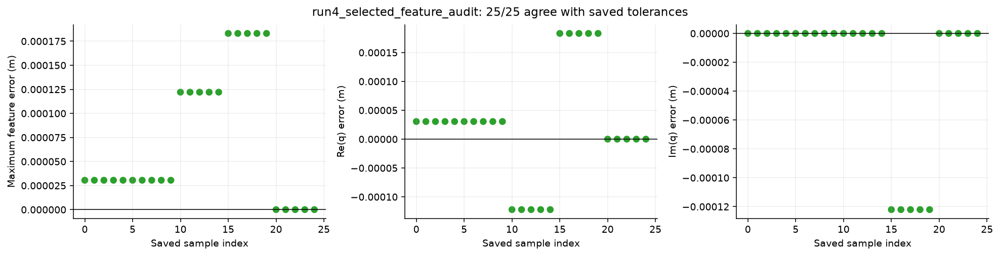

audit,group_id,h5_key,max_feature_abs_error,q_real_error,q_imag_error,matches_tolerance,trace_valid
run4_selected_feature_audit,round:1:0,sim_0,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:1:0,sim_1,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:1:0,sim_2,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:1:0,sim_3,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:1:0,sim_4,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:10:0,sim_0,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:10:0,sim_1,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:10:0,sim_2,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:10:0,sim_3,3.05176e-05,3.05176e-05,0,True,True
run4_selected_feature_audit,round:10:0,sim_4,3.05176e-05,3.05176e-05,0,True,True


In [5]:
feature_checks = []
for name, record in audits.items():
    rows = record['features']
    if not rows:
        continue
    feature_checks.extend({'audit': name, **row} for row in rows)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
    colors = ['tab:green' if r.get('matches_tolerance') and r.get('trace_valid') else 'tab:red' for r in rows]
    for ax, field, label in zip(axes,
            ['max_feature_abs_error', 'q_real_error', 'q_imag_error'],
            ['Maximum feature error (m)', 'Re(q) error (m)', 'Im(q) error (m)']):
        ax.scatter(range(len(rows)), values(rows, field), c=colors)
        ax.axhline(0, color='black', lw=0.8)
        ax.set(xlabel='Saved sample index', ylabel=label)
    passed = sum(bool(r.get('matches_tolerance')) for r in rows)
    fig.suptitle(f'{name}: {passed}/{len(rows)} agree with saved tolerances')
    show_figure(fig, f'feature_check_{name}')
table(feature_checks, title='All reconstructed-feature checks')


## Run 4: matched designs, held-out validation, and online optimization

The [written findings](RUN4_FINDINGS.md) and [HTML overview](RUN4_FINDINGS.html)
separate the matched initial-design comparison, held-out validation, original
online PSO decisions, and later checkpoint replay. Runs 3 and 4 reuse the same
initial geometric designs and production split membership. They change the
production training objective and subsequently visit different online designs;
this is a matched-start comparison rather than an isolated causal experiment.

`base_on_initial` preserves each model's original split metadata. Both the full
`validation` cohort of 20 groups and its `validation_valid_fixed_q` subset of
15 groups appear in the diagnostic tables. Replay on run 4 feedback asks how
saved checkpoints reproduce those labels, including feedback seen during
training; original online logs record the predictions available at the time.


# Run 4 surrogate diagnostics

Run 4 improves substantially over run 3 on matched initial validation designs and
finds better Finesse-verified PSO designs. Its best saved full cost is
**0.0102834 at round 10**,
39.3% lower than run 3's best.
Signed-difference MAE on the same valid initial validation designs falls by
**53.2%**. However, the model still misses symmetric
response shape, often understates sensitivity, and does not improve difference
accuracy consistently with each feedback update. Low difference MAE alone is
misleading when the true changes are very small.

This analysis uses saved Finesse labels, production checkpoints and captured online
evaluations. Separate local experiments use diagnostic checkpoints. The notebook
can be refreshed from these artifacts without training or optical power solves.

## Data, features, and the actual intervention

The full run 4 audit contains **140 groups / 700 rows**:
500 initial rows and 200 feedback rows. There are 118 valid fixed-q groups.
The initial data has 78 valid groups and 22 invalid groups, 104 zero-power rows,
and 230 rows in the saved 282.09 ± 0.01 W center band. All 40 feedback groups are
valid fixed-q groups. Zero labels alone cannot identify instability or solver failure.

Run 3 and run 4 have identical parsed initial features and labels, initial design
splits (80 training / 20 validation), normalization, architecture, and seed 9302.
Both use 1,000 base epochs, batch size 32, 20 feedback epochs, and automatic newest-row
weight 100. Matching these settings makes this comparison more controlled than run 2
versus run 3. Both manifests record a dirty working tree; byte-identical initial
weights and execution determinism were not independently recorded.

Run 4 uses production **`nominal_delta`** supervision. It directly supervises nominal
power and signed partner-minus-nominal differences. This also changes which rows
receive the direct power criterion: partner rows reference their nominal design,
rather than retaining the old direct power penalty on every partner label. It is a
combined objective change, rather than simply adding one term to the old row loss.
The fixed training-derived difference scale is approximately **8.9252 W**, reused
for feedback. Sub-0.1 W responses therefore have small quadratic loss contributions.
Checkpoint selection still uses all-row validation **power loss**, without an explicit
signed-difference selection term. Invalid-q training transitions remain in production
training and in the scale calculation.
Invalid-q partners contribute 27.34% of squared initial training differences;
valid-only RMS is still 8.57323 W, so removing invalid groups alone would change
this scale only modestly.

All 25 selected feature reconstructions from rounds
1, 10, 20, 30, and 40 passed the saved `rtol=2e-4, atol=0.05` tolerances. These checks
use beam tracing and support feature plumbing; they do not validate optical labels.

Evidence: [full data audit](outputs/run4_audit/audit.json),
[feature audit](outputs/run4_selected_feature_audit/audit.json),
[training audit and provenance](outputs/run4_training_audit/training_audit.json).

## Matched initial validation improves, but remains imperfect

Both base models are evaluated on exactly the same **15 valid held-out designs**
(75 rows / 60 directional responses). These validation designs were excluded from
weight updates but used for production checkpoint selection; this is not an independent test.
The five invalid-q validation designs are excluded here and retained in the separate
all-row production metrics. Only 10 directional labels exceed the 0.1 W sign threshold.

| Base checkpoint | Power MAE (W) | ΔPower MAE (W) | Perturbation-cost MAE (W/m) | Significant signs correct |
| --- | ---: | ---: | ---: | ---: |
| Run 3 base | 7.12385 | 0.642019 | 0.23489 | 2/10 |
| Run 4 base | 6.25405 | 0.30074 | 0.110748 | 6/10 |

The error magnitudes and significant signs improve. The symmetric response problem
remains: on these 15 designs, Finesse decreases in both ITM directions for 11 designs
and both ETM directions for 13; the run 4 base model predicts **zero** both-decrease
pairs for either mirror. Most initial true differences are tiny: only 52 of the 312
valid initial directional labels exceed 0.1 W. The baseline comparison below helps
distinguish a small error average from learning those changes.

Production selected run 4 epoch 780 using the 20-design all-row validation power
loss. Its recorded all-row power MAE is 4.74142 W and difference MAE 0.225926 W;
those values use a different cohort from the valid-only table above. Loss values
and selection criteria should not be compared as if the objectives were unchanged.

## Accuracy on the same 40 run 4 feedback designs

All checkpoints below see the same saved geometries and labels. The final run 4
checkpoint has trained on all these feedback labels, so its result measures replay
reconstruction. Earlier models did not train on these labels, but the geometries
were selected adaptively by run 4's search.

| Checkpoint | Power MAE (W) | ΔPower MAE (W) | Perturbation-cost MAE (W/m) | Significant signs correct |
| --- | ---: | ---: | ---: | ---: |
| Run 3 base | 2.13289 | 0.935642 | 0.273561 | 7/47 |
| Run 3 round 40 | 6.76059 | 0.898612 | 0.258706 | 7/47 |
| Run 4 base | 4.87073 | 0.103184 | 0.00807261 | 9/47 |
| Run 4 round 40 (replay) | 1.18294 | 0.0934732 | 0.0178189 | 40/47 |

Run 4's base model is much better than run 3's on difference magnitudes at these
points. Final replay improves nominal power and significant signs, yet its
perturbation-cost MAE is higher than the run 4 base model's. In final replay,
all 40 significant ETM+ signs are correct and all seven significant ETM− signs are
wrong; neither ITM direction has a significant true difference in this cohort.
Finesse decreases in both ETM directions for **32/40** feedback designs;
the final checkpoint predicts **0/40** such pairs.
The improved ETM+ signs therefore coexist with missing symmetric curvature.
The search visits a region dominated by much smaller responses than run 3's trajectory.
[Final replay response shape](outputs/run4_comparison/final_response_shape.json).

| Evaluation | Model ΔPower MAE (W) | Zero-response ΔPower MAE (W) |
| --- | ---: | ---: |
| Run3 base / valid initial validation | 0.642019 | 0.039697 |
| Run4 base / valid initial validation | 0.30074 | 0.039697 |
| Run4 base / run4 feedback | 0.103184 | 0.0725293 |
| Run4 final / run4 feedback replay | 0.0934732 | 0.0725293 |
| Run4 original online | 0.0723349 | 0.0725293 |

The baseline predicts ΔPower = 0 everywhere. Its error is mean absolute true
ΔPower; it says nothing about nominal-power accuracy. These values show why the
observed magnitude and sign improvements still do not establish an accurate local
response model. [Response baseline records](outputs/run4_comparison/response_baselines.csv).
Both base checkpoints on valid initial validation and the final checkpoint on
feedback replay have higher difference MAE than simply predicting zero response.

At round 40, replay through the final checkpoint gives:

| Direction | Finesse power (W) | Final MLP power (W) | Finesse ΔPower (W) | Final MLP ΔPower (W) |
| --- | ---: | ---: | ---: | ---: |
| nominal | 282.014 | 283.069 | 0 | 0 |
| ITM_plus | 282.003 | 283.073 | -0.0109718 | 0.00392821 |
| ITM_minus | 282.018 | 283.069 | 0.00407539 | 0.000541819 |
| ETM_plus | 281.751 | 283.063 | -0.262587 | -0.00582449 |
| ETM_minus | 281.899 | 283.072 | -0.115191 | 0.00298002 |

The true perturbation cost is 0.031198 W/m, while final replay predicts about
0.00114383 W/m, approximately 27 times too small. Across the 40 matching feedback
updates, nominal-power MAE changes **2.35016 → 2.2145 W**, while
signed-difference MAE changes **0.0723571 → 0.0731025 W**. Individual
updates therefore offer little average difference improvement.

Original online predictions are distinct from replay reconstructed from float32
saved features. Tiny rounded differences can change signs: original online has
32/47 significant signs correct, versus 30/47 in matching pre-update replay.

Evidence: [checkpoint comparison](outputs/run4_comparison/comparison.json),
[per-update feedback records](outputs/run4_training_audit/feedback_updates.csv).

## The actual PSO outcome is substantially better

Costs use each saved full objective:

`0.5 / nominal_power + 0.5 * sum(abs(ΔPower) / ROC_step)`.

| Run | Best true cost | Mean true cost | Last true cost | Online nominal MAE (W) | Online ΔPower MAE (W) | Significant signs correct |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Run 3 | 0.0169407 (round 4) | 2.9962 | 4.77661 | 11.3952 | 9.92912 | 48/131 |
| Run 4 | 0.0102834 (round 10) | 0.0136565 | 0.0173719 | 2.35021 | 0.0723349 | 32/47 |

Run 4's mean true cost is about 219 times lower,
and its best cost is 39.3% lower.
Each run chose its own trajectory, so this measures the actual optimization outcome
and cannot by itself isolate the loss change. All captured costs were reconstructed
from original powers, exact ROC steps, and weights and checked against saved costs.

Run 4 searches ITM ROC −3169 to −2419 m and ETM ROC 3774 to 3868 m, away from the
upper ITM bound repeatedly selected by run 3. Its best saved design (round 10) has
nominal power 281.940 W at ITM ROC −2575.356 m / ETM ROC 3788.523 m. The original
surrogate cost there is 0.00196104 versus true 0.0102834. At round 40, original
online cost is 0.00225026 versus true 0.0173719 (about 7.72 times larger).
The median true/predicted cost ratio remains about 6.08. Better verified designs
coexist with systematic optimism about sensitivity.

![Original online costs and nominal powers](outputs/run4_comparison/online_cost_and_power.png)

[All original PSO selections and cost components](outputs/run4_comparison/online_rounds.csv).

## Controlled local fits and transfer limitations

The same local diagnostic as run 3 fits rounds 1, 10, 20, 30, and 40 (25 rows),
one seed 9302, for up to 2,000 epochs. Loss variants within an initialization share
initial weights, scaling and optimizer settings. The diagnostic `paired` objective
is row log-power plus signed-difference supervision; **it differs from production
`nominal_delta`**. Its difference scale is derived from the selected training set.
Checkpoint monitoring uses training power MAE / power RMS plus difference MAE /
floored difference RMS. These are local fitting tests, not a global replacement.

| Initialization / scaling | Diagnostic loss | Selected epoch | Power MAE (W) | ΔPower MAE (W) |
| --- | --- | ---: | ---: | ---: |
| Fresh / local scaling | center_focused | 0 | 280.94 | 0.0700343 |
| Fresh / local scaling | log_smooth_l1 | 0 | 280.94 | 0.0700343 |
| Fresh / local scaling | paired | 1850 | 4.17671 | 0.0147322 |
| Round 40 / original scaling | center_focused | 0 | 1.25328 | 0.0946254 |
| Round 40 / original scaling | log_smooth_l1 | 0 | 1.25328 | 0.0946254 |
| Round 40 / original scaling | paired | 1750 | 0.426908 | 0.015795 |

The row-power variants select **epoch 0** for both initializations. The fresh
initial model has extremely poor absolute powers but nearly flat differences;
the combined score can favor it over later power fits because the true differences
are tiny. Those rows describe retained initial checkpoints, not successful row-power
training. Paired supervision improves both local power and difference accuracy.

Fresh diagnostic checkpoints were then evaluated without retraining on the other
35 feedback designs (175 rows):

| Fresh diagnostic checkpoint | Power MAE (W) | Max power error (W) | ΔPower MAE (W) | Max ΔPower error (W) |
| --- | ---: | ---: | ---: | ---: |
| Fresh row-power | 280.921 | 281.234 | 0.0716717 | 0.401067 |
| Fresh paired | 8.43388 | 44.9436 | 0.236029 | 3.73229 |

Transfer groups remain correlated with the saved PSO collection policy. Good local
or nearby-transfer scores do not establish coverage across the global search domain.
Here the paired model's difference MAE increases from 0.0147 W on fitted groups to
0.236 W on transfer, with a 3.73 W maximum difference error. The retained row-power
initial model stays almost flat and has roughly 281 W absolute-power error.

Evidence: [fresh fit results](outputs/run4_five_groups_fresh/summary.csv),
[warm fit results](outputs/run4_five_groups_warm/summary.csv),
[row-power transfer](outputs/run4_transfer_center_focused/metrics.json),
[paired transfer](outputs/run4_transfer_paired/metrics.json).

## Interpretation and next experiment

The nominal/difference objective change is supported by better matched-validation
metrics and markedly better Finesse-verified optimization results. Remaining evidence
points to weak small-response supervision, missing symmetric curvature, and a mismatch
between the training objective and power-only checkpoint selection. These mechanisms
are plausible explanations, rather than independently isolated causes.

A useful next controlled experiment would preserve the complete initial split and
global normalization, compare response scaling and a validation power/difference
selection criterion, and report constant-response baselines alongside signed errors,
sign counts and verified full costs. Validate on new whole designs spanning the
search domain before interpreting nearby replay or local fits as global accuracy.
Keep the best Finesse-verified design alongside the latest round.


comparison,run,checkpoint,split,groups,rows,power_mae,nominal_power_mae,delta_mae,sign_count,sign_correct,sign_accuracy,perturbation_cost_mae,full_cost_mae,predicted_full_cost_mean,true_full_cost_mean,interpretation
original_online_own_selected_points,3,base for round1; roundN-1 for roundN,online,40,200,17.8715,11.3952,9.92912,131,48,0.366412,5.9183,2.95993,0.0423476,2.9962,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
original_online_own_selected_points,4,base for round1; roundN-1 for roundN,online,40,200,2.38966,2.35021,0.0723349,47,32,0.680851,0.0229941,0.01151,0.00214655,0.0136565,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
same_target_feedback_geometries,3,base,feedback,40,200,2.13289,2.00188,0.935642,47,7,0.148936,0.273561,0.136768,0.150425,0.0136565,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,3,round40,feedback,40,200,6.76059,6.70426,0.898612,47,7,0.148936,0.258706,0.129312,0.142968,0.0136565,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
own_initial_checkpoint_split,3,base,training,80,400,4.57823,3.63174,2.0875,48,26,0.541667,1.09304,0.546319,0.164908,0.46105,"Training fit, including all rows production trained."
own_initial_checkpoint_split,3,base,training_valid_fixed_q,63,315,5.35676,4.347,2.28532,42,21,0.5,1.0099,0.504985,0.157196,0.408034,"Training fit, including all rows production trained. Only valid fixed-q groups; overlaps corresponding all-row split."
own_initial_checkpoint_split,3,base,validation,20,100,5.38223,5.25234,0.481991,10,2,0.2,0.23489,0.117491,0.12748,0.00998867,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test.
own_initial_checkpoint_split,3,base,validation_valid_fixed_q,15,75,7.12385,6.95065,0.642019,10,2,0.2,0.23489,0.117491,0.12748,0.00998867,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test. Only valid fixed-q groups; overlaps corresponding all-row split.
same_target_feedback_geometries,4,base,feedback,40,200,4.87073,4.81719,0.103184,47,9,0.191489,0.00807261,0.00403703,0.0115779,0.0136565,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,4,round40,feedback,40,200,1.18294,1.18942,0.0934732,47,40,0.851064,0.0178189,0.00891597,0.0134223,0.0136565,"Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization."


evaluation,response_count,model_delta_mae_w,zero_response_delta_mae_w,predicted_mean_abs_delta_w,note
Run3 base / valid initial validation,60,0.642019,0.039697,0.619397,Zero-response baseline predicts delta=0; it does not predict nominal power.
Run4 base / valid initial validation,60,0.30074,0.039697,0.301667,Zero-response baseline predicts delta=0; it does not predict nominal power.
Run4 base / run4 feedback,160,0.103184,0.0725293,0.0567935,Zero-response baseline predicts delta=0; it does not predict nominal power.
Run4 final / run4 feedback replay,160,0.0934732,0.0725293,0.0625919,Zero-response baseline predicts delta=0; it does not predict nominal power.
Run4 original online,160,0.0723349,0.0725293,0.00209255,Zero-response baseline predicts delta=0; it does not predict nominal power.


run,round,group_id,itm_roc,etm_roc,model_path,checkpoint_round,evaluation_role,training_exposure,cost_mode,power_weight,perturbation_weight,delta_itm,delta_etm,predicted_power_cost,predicted_perturbation_cost,predicted_weighted_power_cost,predicted_weighted_perturbation_cost,predicted_total_cost,true_power_cost,true_perturbation_cost,true_weighted_power_cost,true_weighted_perturbation_cost,true_total_cost,nominal_power,predicted_nominal_power,nominal_power_error,delta_mae,sign_count,sign_correct,true_to_predicted_cost_ratio,true_weighted_power_fraction
3,1,round:1:0,-1434,3446.14,/home/xuesi.ma/ligo-opt/MLP/models/run3/base_500_mlp.pt,0,original_online_before_feedback,Own initial training rows and feedback rounds 1-0,full,0.5,0.5,4.7322,11.3723,0.00405097,0.0652657,0.00202548,0.0326329,0.0346583,0.00356276,0.0426521,0.00178138,0.0213261,0.0231074,280.681,246.855,-33.8267,0.198554,0,0,0.666721,0.0770912
3,2,round:2:0,-1434,3511.81,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round1.pt,1,original_online_before_feedback,Own initial training rows and feedback rounds 1-1,full,0.5,0.5,4.7322,11.589,0.00394642,0.0892658,0.00197321,0.0446329,0.0466061,0.00355308,0.0458918,0.00177654,0.0229459,0.0247224,281.446,253.394,-28.0517,0.384345,1,0,0.530454,0.0718595
3,3,round:3:0,-1434,3555.04,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round2.pt,2,original_online_before_feedback,Own initial training rows and feedback rounds 1-2,full,0.5,0.5,4.7322,11.7316,0.00390091,0.104505,0.00195046,0.0522523,0.0542027,0.00357875,0.118499,0.00178937,0.0592493,0.0610387,279.427,256.35,-23.0772,0.650837,2,0,1.12612,0.0293154
3,4,round:4:0,-4134,4245,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round3.pt,3,original_online_before_feedback,Own initial training rows and feedback rounds 1-3,full,0.5,0.5,13.6422,14.0085,0.00361525,0.115883,0.00180762,0.0579415,0.0597492,0.00354492,0.0303364,0.00177246,0.0151682,0.0169407,282.094,276.606,-5.48792,0.425033,2,1,0.28353,0.104627
3,5,round:5:0,-1434,3569.97,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round4.pt,4,original_online_before_feedback,Own initial training rows and feedback rounds 1-4,full,0.5,0.5,4.7322,11.7809,0.00390826,0.106158,0.00195413,0.0530788,0.0550329,0.00359046,0.141822,0.00179523,0.0709112,0.0727065,278.516,255.869,-22.6471,0.705951,2,0,1.32114,0.0246915
3,6,round:6:0,-1434,3582.66,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round5.pt,5,original_online_before_feedback,Own initial training rows and feedback rounds 1-5,full,0.5,0.5,4.7322,11.8228,0.00388835,0.114917,0.00194418,0.0574587,0.0594029,0.00360144,0.168179,0.00180072,0.0840897,0.0858904,277.666,257.178,-20.488,0.787767,2,0,1.4459,0.0209653
3,7,round:7:0,-1434,2570.18,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round6.pt,6,original_online_before_feedback,Own initial training rows and feedback rounds 1-6,full,0.5,0.5,4.7322,8.48161,0.0287464,0.0843753,0.0143732,0.0421877,0.0565609,0.0900731,5.2386,0.0450366,2.6193,2.66434,11.1021,34.787,23.6849,8.59246,4,0,47.1057,0.0169035
3,8,round:8:0,-1434,2960.8,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round7.pt,7,original_online_before_feedback,Own initial training rows and feedback rounds 1-7,full,0.5,0.5,4.7322,9.77064,0.00432005,0.0599379,0.00216002,0.0299689,0.032129,0.00355524,0.0364887,0.00177762,0.0182444,0.020022,281.275,231.479,-49.7963,0.124759,0,0,0.623176,0.0887833
3,9,round:9:0,-1434,2587.94,/home/xuesi.ma/ligo-opt/MLP/models/run3/power_predictor_ligoParams_finetuned_round8.pt,8,original_online_before_feedback,Own initial training rows and feedback rounds 1-8,full,0.5,0.5,4.7322,8.54019,0.0316718,0.0518683,0.0158359,0.0259342,0.04177,0.029449,8.17615,0.0147245,4.08808,4.1028,33.9571,31.5739,-2.38319,13.4986,4,2,98.2236,0.00358888
3,10,round:10:0,-1434,2586.06,/h

**run4_comparison: online_cost_and_power**

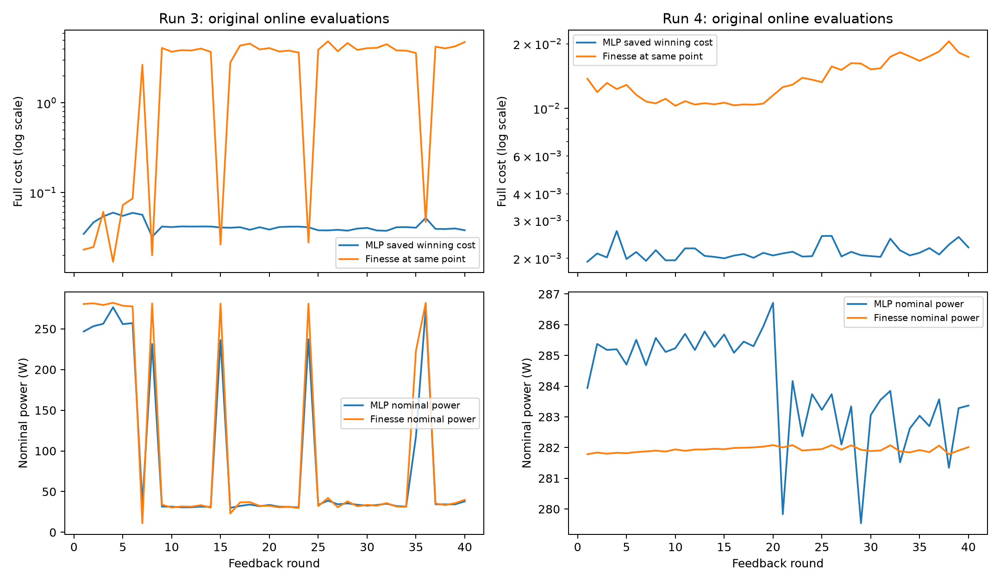

**run4_comparison: online_roc_coverage**

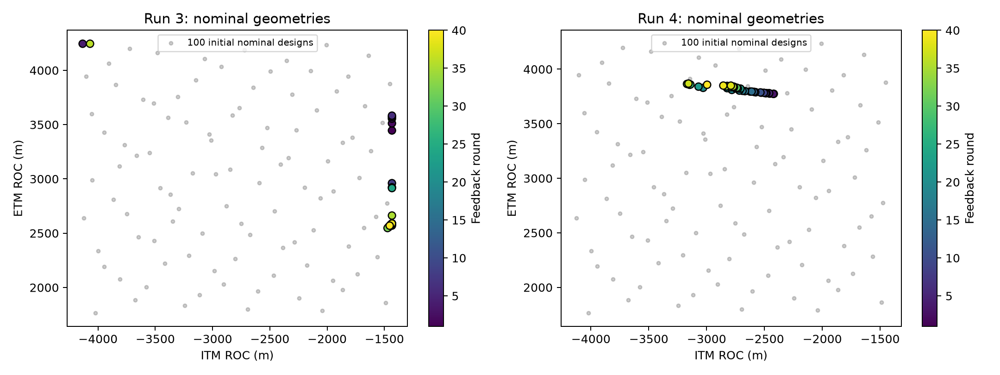

**run4_comparison: same_geometry_delta_errors**

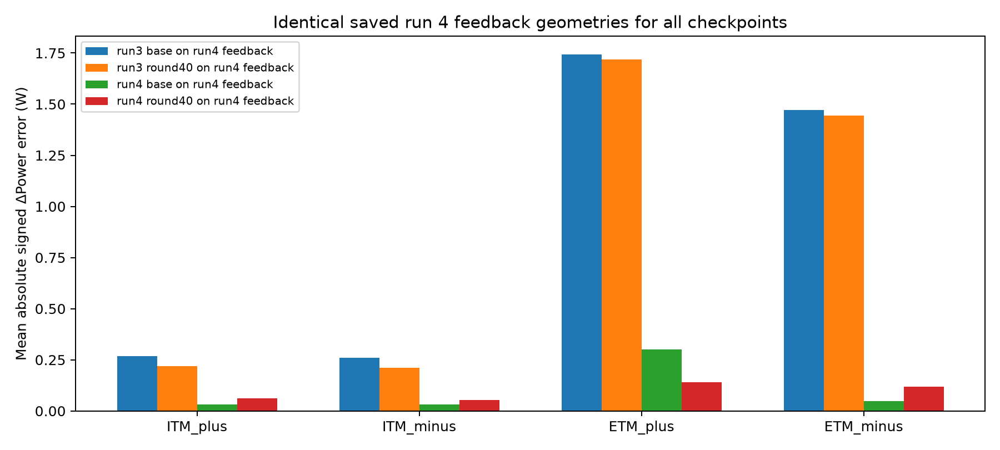

round,stage,valid_fixed_q,nominal_itm_roc_m,nominal_etm_roc_m,true_nominal_power,predicted_nominal_power,nominal_power_abs_error,power_mae,delta_mae,sign_count,sign_accuracy,group_id,true_perturbation_cost,predicted_perturbation_cost,valid_perturbation_cost,best_epoch,newest_row_weight
1,pre,True,-2418.82,3774.52,281.784,283.941,2.15758,2.19502,0.0696474,1,1,round:1:0,0.0239658,0.000395818,True,20,100
1,post,True,-2418.82,3774.52,281.784,285.181,3.39765,3.43492,0.0651437,1,1,round:1:0,0.0239658,0.001872,True,20,100
2,pre,True,-2453.45,3776.22,281.839,285.375,3.53631,3.57256,0.0609262,1,0,round:2:0,0.0202796,0.000661772,True,15,100
2,post,True,-2453.45,3776.22,281.839,285.391,3.55229,3.58873,0.0633503,1,0,round:2:0,0.0202796,0.00153193,True,15,100
3,pre,True,-2422.92,3773.65,281.8,285.181,3.3806,3.41679,0.0649936,1,1,round:3:0,0.0227343,0.000378686,True,10,100
3,post,True,-2422.92,3773.65,281.8,284.862,3.062,3.09828,0.065506,1,1,round:3:0,0.0227343,0.00143971,True,10,100
4,pre,True,-2460.6,3778.86,281.831,285.202,3.37079,3.40829,0.066819,1,0,round:4:0,0.0210727,0.00184441,True,10,100
4,post,True,-2460.6,3778.86,281.831,284.647,2.81548,2.8527,0.0612925,1,1,round:4:0,0.0210727,0.000929203,True,10,100
5,pre,True,-2458.89,3780.14,281.817,284.703,2.88613,2.92411,0.0640359,1,1,round:5:0,0.0221983,0.000451841,True,1,100
5,post,True,-2458.89,3780.14,281.817,285.415,3.59816,3.63636,0.0628045,1,1,round:5:0,0.0221983,0.000849397,True,1,100


In [6]:
run4_findings_path = DIAGNOSTICS_DIR / 'RUN4_FINDINGS.md'
if run4_findings_path.exists():
    display(Markdown(run4_findings_path.read_text()))
for comparison_path in sorted(OUTPUTS_DIR.rglob('comparison.json')):
    name = comparison_path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if not included(name):
        continue
    comparison = read_json(comparison_path)
    json_panel(f'{name}: full comparison and source hashes', comparison)
    table(read_csv(comparison_path.parent / 'summary.csv'),
          title=f'{name}: checkpoint and original online metrics', collapsed=True)
    table(read_csv(comparison_path.parent / 'response_baselines.csv'),
          title=f'{name}: zero-response baselines on the same saved labels')
    table(read_csv(comparison_path.parent / 'online_rounds.csv'),
          title=f'{name}: every original PSO selection and cost component', collapsed=True)
    for figure_path in sorted(comparison_path.parent.glob('*.png')):
        display(Markdown(f'**{name}: {figure_path.stem}**'))
        display(Image(filename=str(figure_path)))
for training_path in sorted(OUTPUTS_DIR.rglob('training_audit.json')):
    name = training_path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if included(name):
        json_panel(f'{name}: matched initial designs, symmetry, and feedback updates',
                   read_json(training_path))
        table(read_csv(training_path.parent / 'feedback_updates.csv'),
              title=f'{name}: before/after every feedback update', collapsed=True)


## Experiment conditions and comparable results

Compare checkpoints on the same saved geometry, detector, and split. Fresh
five-group fits use local scaling; warm fits reuse the run 4 round-40 checkpoint
and its scaling. Both initialization and normalization change, so their
difference cannot be assigned to either factor alone. These diagnostic loss
variants retain the older `paired` row log-power plus delta implementation;
they do not reproduce production `nominal_delta` training.

Transfer uses the remaining feedback groups outside the five fitted groups.
Those labels are unseen by the tiny-fit stage; a warm checkpoint can already
carry exposure through its earlier production training. The saved conditions,
checkpoint metadata, and source hashes below make that scope explicit.


In [7]:
condition_rows, initialization_rows = [], []
for name, experiment in experiments.items():
    config, provenance = experiment['config'], experiment['provenance']
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == name]
    first = selected_runs[0]
    sizes = {split: stats['groups'] for split, stats in first['metrics'].get('splits', {}).items()}
    excluded = provenance.get('excluded_invalid_fixed_q_groups', first['metrics'].get('excluded', {}))
    condition_rows.append({
        'experiment': name, 'scope': experiment['scope'], 'detector': config.get('detector'),
        'initial_checkpoint': first['metrics'].get('checkpoint') or config.get('initial_checkpoint') or 'fresh weights',
        'normalization': 'checkpoint (evaluation)' if first['metrics'].get('checkpoint') else config.get('normalization'),
        'epochs': config.get('epochs') if first['history'] else None,
        'monitor_split': first['metrics'].get('monitor_split'),
        'groups_by_split': sizes, 'excluded_groups': {k: len(v) for k, v in excluded.items()},
        'power_scale_W': provenance.get('power_scale_w'), 'delta_scale_W': provenance.get('delta_scale_w'),
    })
    seeds = sorted({r['config'].get('seed') for r in selected_runs if r['config'].get('seed') is not None})
    for seed in seeds:
        hashes = {r['config'].get('initial_state_sha256') for r in selected_runs if r['config'].get('seed') == seed}
        hashes.discard(None)
        initialization_rows.append({'experiment': name, 'seed': seed, 'recorded_initial_states': len(hashes),
                                    'same_start_across_variants': len(hashes) == 1 if hashes else None})
table(condition_rows, title='Saved experimental conditions')
table(initialization_rows, title='Initialization consistency within each experiment / seed')
table(metric_rows, columns=['experiment', 'variant', 'seed', 'split', 'detector', 'best_epoch',
    'groups', 'rows', 'power_mae', 'power_max_abs_error', 'delta_mae', 'delta_max_abs_error',
    'sign_accuracy', 'sign_count', 'sign_threshold_w', 'perturbation_cost_mae',
    'valid_cost_groups', 'invalid_cost_groups'], title='All saved metrics')


experiment,scope,detector,initial_checkpoint,normalization,epochs,monitor_split,groups_by_split,excluded_groups,power_scale_W,delta_scale_W
run4_comparison/run3_base_on_initial,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/MLP/models/run3/base_500_mlp.pt,checkpoint (evaluation),—,—,"{'training': 80, 'training_valid_fixed_q': 63, 'validation': 20, 'validation_valid_fixed_q': 15}","{'training': 0, 'training_valid_fixed_q': 0, 'validation': 0, 'validation_valid_fixed_q': 0}",—,—
run4_comparison,standalone checkpoint evaluation,—,/home/xuesi.ma/ligo-opt/MLP/models/run3/base_500_mlp.pt,checkpoint (evaluation),—,—,{'feedback': 40},{'feedback': 0},—,—
run4_comparison/run4_base_on_initial,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/MLP/models/run4/base_500_mlp.pt,checkpoint (evaluation),—,—,"{'training': 80, 'training_valid_fixed_q': 63, 'validation': 20, 'validation_valid_fixed_q': 15}","{'training': 0, 'training_valid_fixed_q': 0, 'validation': 0, 'validation_valid_fixed_q': 0}",—,—
run4_five_groups_fresh,training-set fit,p_ITM_p2_i,fresh weights,training,2000,train,{'train': 5},{'train': 0},281.889,1
run4_five_groups_warm,training-set fit,p_ITM_p2_i,MLP/models/run4/power_predictor_ligoParams_finetuned_round40.pt,checkpoint,2000,train,{'train': 5},{'train': 0},281.889,1
run4_transfer_center_focused,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs/run4_five_groups_fresh/center_focused_seed9302/checkpoint.pt,checkpoint (evaluation),—,—,{'transfer': 35},{'transfer': 0},—,—
run4_transfer_paired,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs/run4_five_groups_fresh/paired_seed9302/checkpoint.pt,checkpoint (evaluation),—,—,{'transfer': 35},{'transfer': 0},—,—


experiment,seed,recorded_initial_states,same_start_across_variants
run4_five_groups_fresh,9302,1,True
run4_five_groups_warm,9302,1,True


experiment,variant,seed,split,detector,best_epoch,groups,rows,power_mae,power_max_abs_error,delta_mae,delta_max_abs_error,sign_accuracy,sign_count,sign_threshold_w,perturbation_cost_mae,valid_cost_groups,invalid_cost_groups
run4_comparison/run3_base_on_initial,checkpoint,—,training,p_ITM_p2_i,—,80,400,4.57823,82.4172,2.0875,67.1701,0.541667,48,0.1,1.09304,64,16
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,p_ITM_p2_i,—,63,315,5.35676,73.1971,2.28532,61.1513,0.5,42,0.1,1.0099,63,0
run4_comparison/run3_base_on_initial,checkpoint,—,validation,p_ITM_p2_i,—,20,100,5.38223,42.8268,0.481991,1.91019,0.2,10,0.1,0.23489,15,5
run4_comparison/run3_base_on_initial,checkpoint,—,validation_valid_fixed_q,p_ITM_p2_i,—,15,75,7.12385,42.8268,0.642019,1.91019,0.2,10,0.1,0.23489,15,0
run4_comparison,checkpoint,—,feedback,p_ITM_p2_i,—,40,200,2.13289,6.45552,0.935642,2.09115,0.148936,47,0.1,0.273561,40,0
run4_comparison,checkpoint,—,feedback,p_ITM_p2_i,—,40,200,6.76059,12.3162,0.898612,2.06713,0.148936,47,0.1,0.258706,40,0
run4_comparison/run4_base_on_initial,checkpoint,—,training,p_ITM_p2_i,—,80,400,4.4777,73.6586,1.71026,66.9551,0.8125,48,0.1,0.944637,64,16
run4_comparison/run4_base_on_initial,checkpoint,—,training_valid_fixed_q,p_ITM_p2_i,—,63,315,5.35661,62.3361,1.86922,61.0632,0.785714,42,0.1,0.869453,63,0
run4_comparison/run4_base_on_initial,checkpoint,—,validation,p_ITM_p2_i,—,20,100,4.74141,39.4798,0.225904,0.904391,0.6,10,0.1,0.110748,15,5
run4_comparison/run4_base_on_initial,checkpoint,—,validation_valid_fixed_q,p_ITM_p2_i,—,15,75,6.25405,39.4798,0.30074,0.904391,0.6,10,0.1,0.110748,15,0


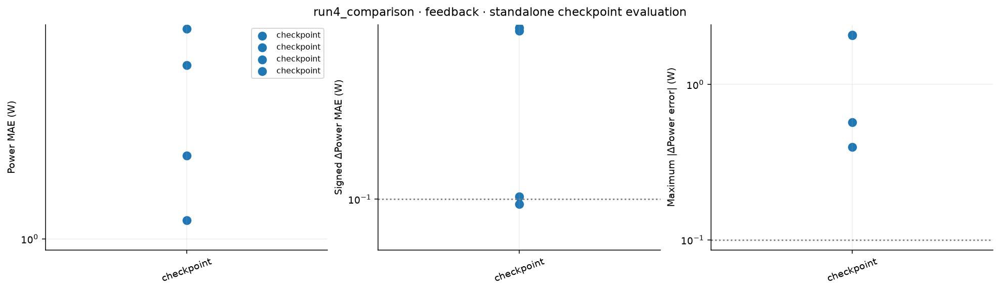

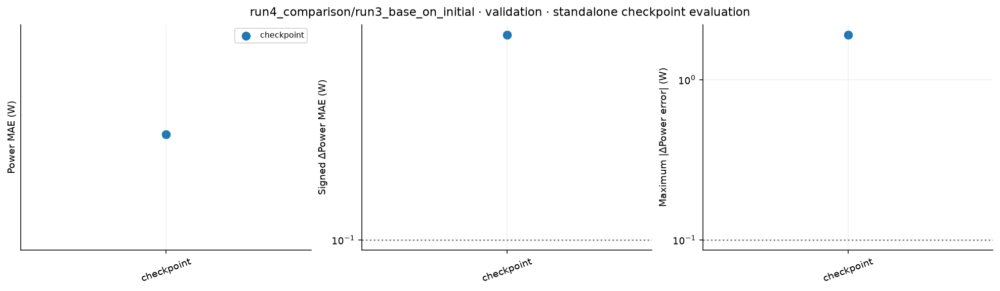

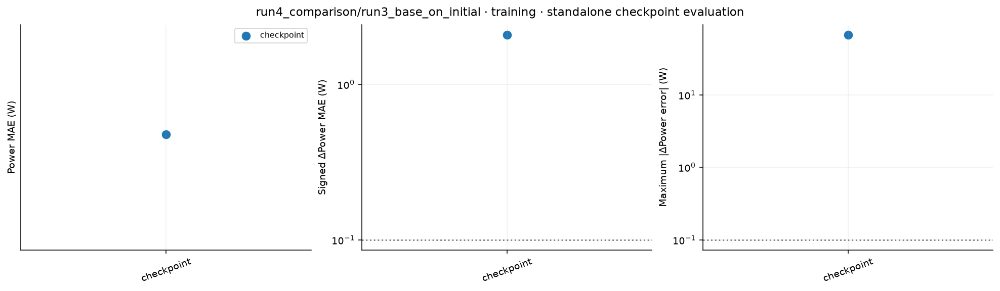

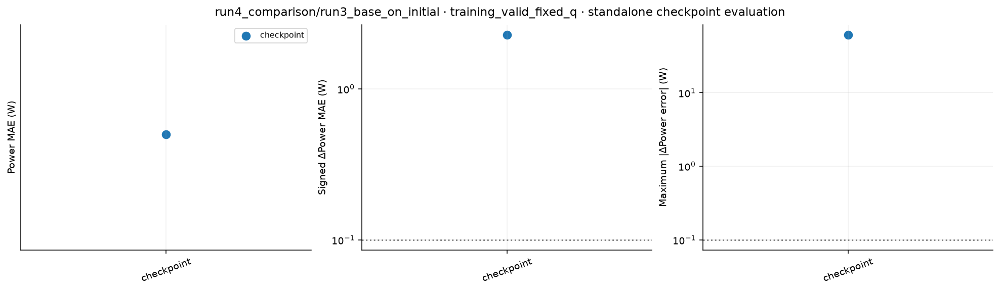

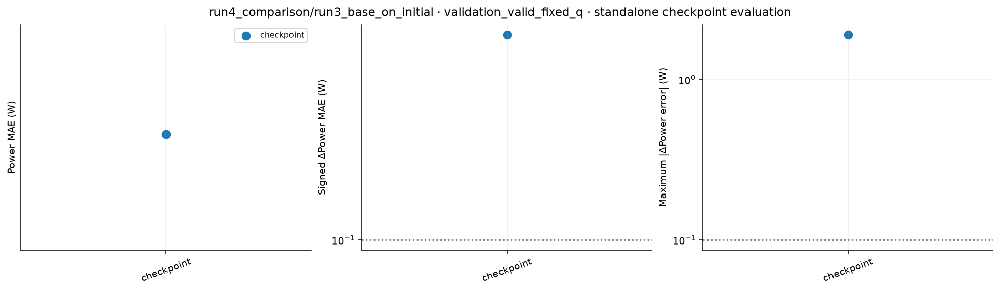

...

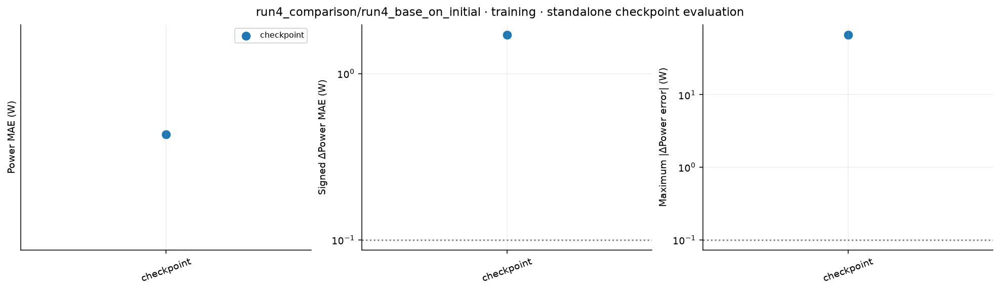

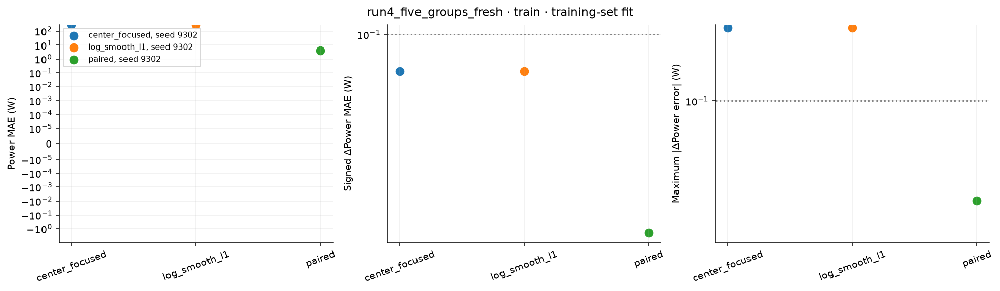

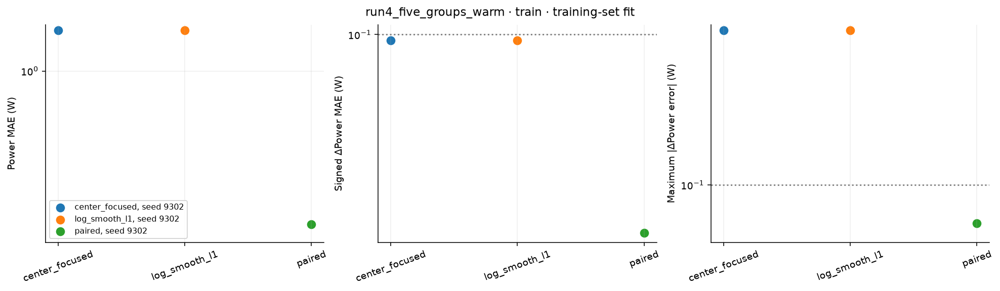

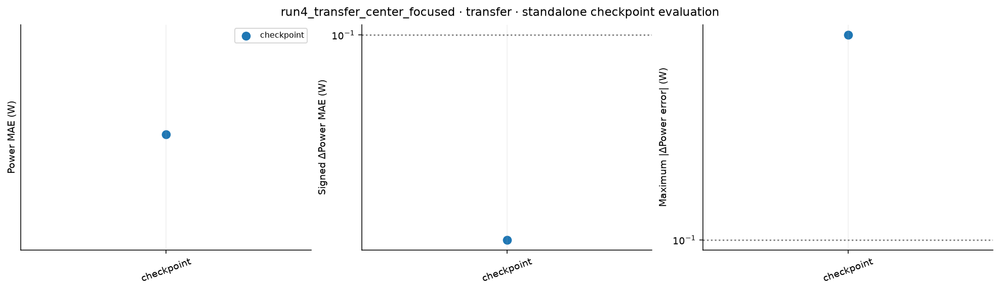

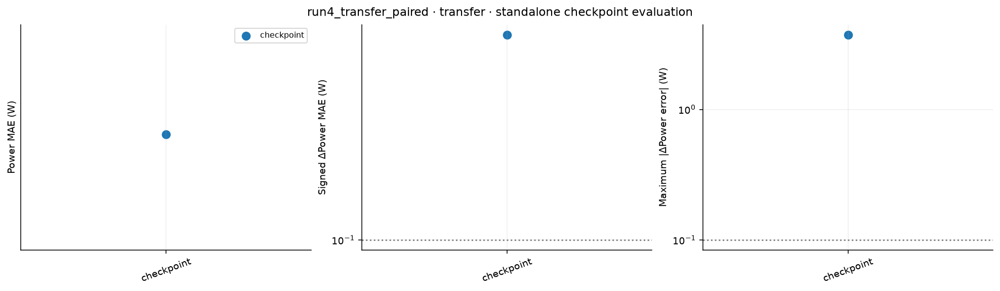

In [8]:
comparison_keys = sorted({(r['experiment'], r['split']) for r in metric_rows},
                         key=lambda key: (key[0], SPLITS.index(key[1]) if key[1] in SPLITS else 99))
for experiment, split in comparison_keys:
    selected = [r for r in metric_rows if r['experiment'] == experiment and r['split'] == split]
    variants = list(dict.fromkeys(r['variant'] for r in selected))
    seeds = list(dict.fromkeys(r['seed'] for r in selected))
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    for ax, field, label in zip(axes,
            ['power_mae', 'delta_mae', 'delta_max_abs_error'],
            ['Power MAE (W)', 'Signed ΔPower MAE (W)', 'Maximum |ΔPower error| (W)']):
        for row in selected:
            offset = (seeds.index(row['seed']) - (len(seeds) - 1) / 2) * 0.08
            ax.scatter(variants.index(row['variant']) + offset, row[field], s=65,
                       color=f'C{variants.index(row["variant"]) % 10}',
                       label=f'{row["variant"]}, seed {row["seed"]}' if row['seed'] is not None else row['variant'])
        ax.set_xticks(range(len(variants)), variants, rotation=20)
        ax.set(ylabel=label, yscale='symlog')
        ax.set_yscale('symlog', linthresh=1e-5)
        if field.startswith('delta'):
            ax.axhline(DELTA_ERROR_TARGET_W, color='grey', ls=':', label='Diagnostic target')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {experiments[experiment]["scope"]}')
    show_figure(fig, f'metrics_{experiment}_{split}')


## Direction-level errors and sign agreement

Both average and worst-case difference errors matter. A small perturbation-cost
error can coexist with wrong individual signs because the cost sums absolute
differences. Blank heatmap cells have no saved metric; sign cells show the number
of differences above the significance threshold.


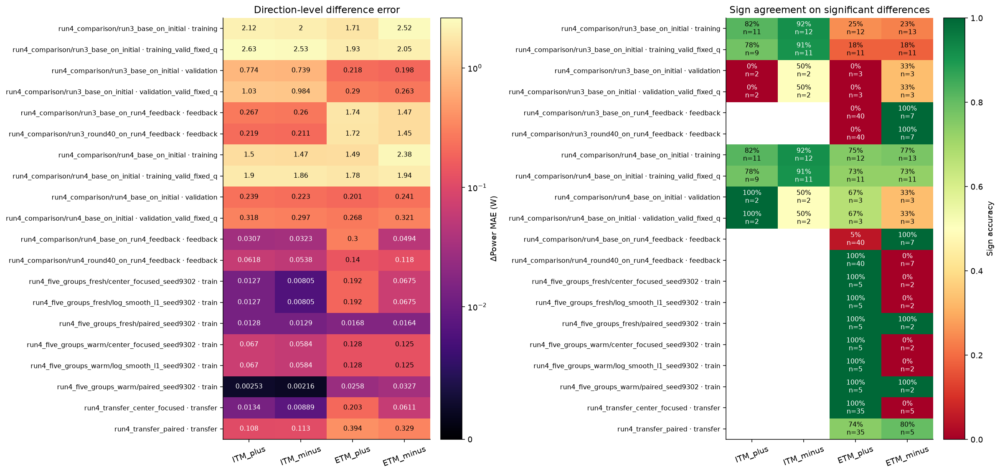

experiment,variant,seed,split,direction,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy
run4_comparison/run3_base_on_initial,checkpoint,—,training,ETM_minus,80,2.51543,67.1701,13,0.230769
run4_comparison/run3_base_on_initial,checkpoint,—,training,ETM_plus,80,1.71438,56.2682,12,0.25
run4_comparison/run3_base_on_initial,checkpoint,—,training,ITM_minus,80,1.99693,55.9605,12,0.916667
run4_comparison/run3_base_on_initial,checkpoint,—,training,ITM_plus,80,2.12327,60.0811,11,0.818182
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,ETM_minus,63,2.05497,61.1513,11,0.181818
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,ETM_plus,63,1.93007,56.2682,11,0.181818
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,ITM_minus,63,2.53019,55.9605,11,0.909091
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,ITM_plus,63,2.62606,60.0811,9,0.777778
run4_comparison/run3_base_on_initial,checkpoint,—,validation,ETM_minus,20,0.197745,1.03679,3,0.333333
run4_comparison/run3_base_on_initial,checkpoint,—,validation,ETM_plus,20,0.217919,1.10889,3,0


In [9]:
direction_keys = list(dict.fromkeys((r['run_id'], r['split']) for r in direction_rows))
present_directions = [d for d in DIRECTIONS if any(r['direction'] == d for r in direction_rows)]
if direction_keys and present_directions:
    shape = (len(direction_keys), len(present_directions))
    error_matrix, sign_matrix = np.full(shape, np.nan), np.full(shape, np.nan)
    counts = np.zeros(shape, dtype=int)
    for row in direction_rows:
        i, j = direction_keys.index((row['run_id'], row['split'])), present_directions.index(row['direction'])
        error_matrix[i, j] = row['delta_mae']
        sign_matrix[i, j] = row['sign_accuracy'] if row['sign_accuracy'] is not None else np.nan
        counts[i, j] = row['sign_count']
    fig, axes = plt.subplots(1, 2, figsize=(17, max(5, 0.4 * len(direction_keys))), constrained_layout=True)
    vmax = max(float(np.nanmax(error_matrix)), 0.01)
    error_image = axes[0].imshow(error_matrix, aspect='auto', cmap='magma',
                           norm=SymLogNorm(linthresh=0.01, vmin=0, vmax=vmax))
    fig.colorbar(error_image, ax=axes[0], label='ΔPower MAE (W)')
    sign_image = axes[1].imshow(sign_matrix, aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
    fig.colorbar(sign_image, ax=axes[1], label='Sign accuracy')
    labels = [f'{run_id} · {split}' for run_id, split in direction_keys]
    for ax in axes:
        ax.set_xticks(range(len(present_directions)), present_directions, rotation=20)
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        ax.grid(False)
    for i in range(shape[0]):
        for j in range(shape[1]):
            if np.isfinite(error_matrix[i, j]):
                rgb = error_image.cmap(error_image.norm(error_matrix[i, j]))[:3]
                color = 'black' if np.dot(rgb, [0.299, 0.587, 0.114]) > 0.5 else 'white'
                axes[0].text(j, i, f'{error_matrix[i, j]:.3g}', ha='center', va='center', color=color, fontsize=8)
            if np.isfinite(sign_matrix[i, j]):
                rgb = sign_image.cmap(sign_image.norm(sign_matrix[i, j]))[:3]
                color = 'black' if np.dot(rgb, [0.299, 0.587, 0.114]) > 0.5 else 'white'
                axes[1].text(j, i, f'{sign_matrix[i, j]:.0%}\nn={counts[i, j]}', ha='center', va='center', color=color, fontsize=8)
    axes[0].set_title('Direction-level difference error')
    axes[1].set_title('Sign agreement on significant differences')
    show_figure(fig, 'direction_metrics')
table(direction_rows, columns=['experiment', 'variant', 'seed', 'split', 'direction', 'count',
    'delta_mae', 'delta_max_abs_error', 'sign_count', 'sign_accuracy'],
    title='Complete direction metrics', collapsed=True)


## Diagnostic fitting trajectories and selected checkpoints

Solid curves show training; dashed curves show the monitored split. Vertical
dotted lines mark the selected epoch. These are the five-group diagnostic fits;
the production checkpoint history is plotted separately below. The diagnostic
`paired` loss combines per-row log-power loss with signed-difference loss.


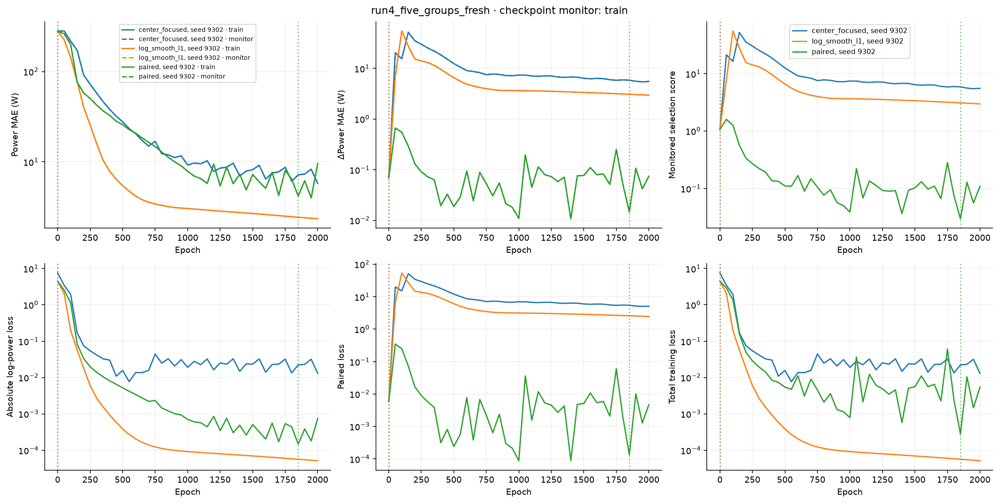

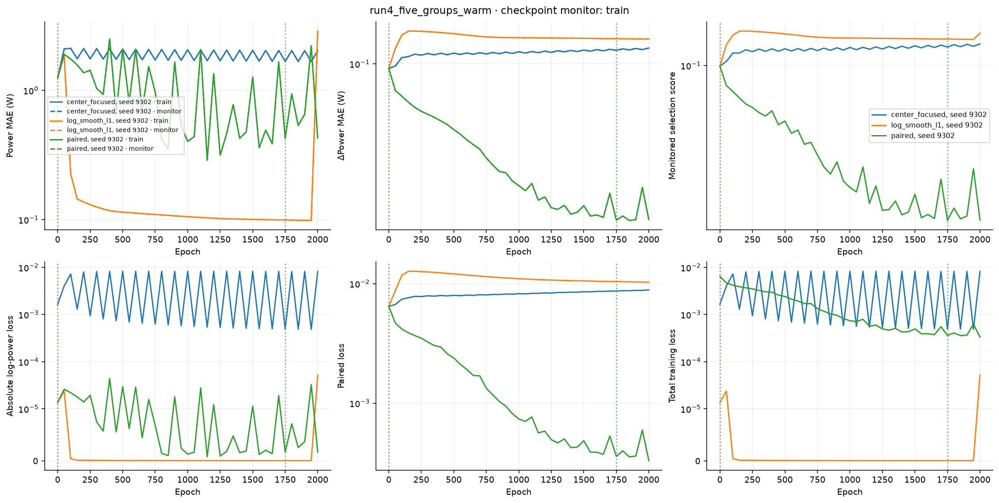

In [10]:
for experiment in experiments:
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == experiment and r['history']]
    if not selected_runs:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    for index, run in enumerate(selected_runs):
        history, tags = run['history'], run['tags']
        color = f'C{index % 10}'
        label = f'{tags["variant"]}, seed {tags["seed"]}'
        epoch = values(history, 'epoch')
        for ax, field, ylabel in zip(axes[0, :2], ['power_mae', 'delta_mae'], ['Power MAE (W)', 'ΔPower MAE (W)']):
            ax.plot(epoch, values(history, f'train_{field}'), color=color, label=f'{label} · train')
            ax.plot(epoch, values(history, f'monitor_{field}'), '--', color=color, label=f'{label} · monitor')
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
        for ax, field, ylabel in zip([axes[0, 2], *axes[1]],
                ['selection_score', 'absolute_loss', 'paired_loss', 'training_loss'],
                ['Monitored selection score', 'Absolute log-power loss', 'Paired loss', 'Total training loss']):
            ax.plot(epoch, values(history, field), color=color, label=label)
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
        best_epoch = run['metrics'].get('best_epoch')
        if best_epoch is not None:
            for ax in axes.flat:
                ax.axvline(best_epoch, color=color, ls=':', alpha=0.6)
    axes[0, 0].legend(fontsize=7)
    axes[0, 2].legend(fontsize=8)
    fig.suptitle(f'{experiment} · checkpoint monitor: {selected_runs[0]["metrics"].get("monitor_split")}')
    show_figure(fig, f'training_{experiment}')


## Production base-training trajectories

These curves read the original production checkpoint histories. Run 4 uses
`nominal_delta`: nominal log-power loss plus a signed perturbation-difference
term. The small diagnostic `paired` fit above retains the older row log-power
plus difference objective, so its loss components and selected epoch have a
different interpretation.

Production history and the diagnostic `validation` split cover all **20 held-out
initial groups**; `validation_valid_fixed_q` retains **15 valid fixed-q groups**. The
initial geometric designs and split membership are matched between runs 3 and
4. Saved run 3 histories omit nominal/delta diagnostics: those values remain
missing here, rather than being inferred or filled with zero. Vertical lines
mark the lowest saved validation-loss epoch for each production history.


run,epoch,training_loss,validation_loss,power_mae,center_power_mae,center_sample_count,nominal_power_mae,delta_mae,delta_max_abs_error,delta_sign_threshold_w,delta_sign_count,delta_sign_accuracy,delta_by_direction,perturbation_cost_mae,training_nominal_loss,training_delta_loss
3,1,25.7071,23.8995,210.662,280.63,45,—,—,—,—,—,—,—,—,—,—
3,5,8.53027,6.51042,488.735,655.579,45,—,—,—,—,—,—,—,—,—,—
3,10,0.841905,0.859635,41.6091,38.2654,45,—,—,—,—,—,—,—,—,—,—
3,15,0.502512,0.483346,32.0647,21.8524,45,—,—,—,—,—,—,—,—,—,—
3,20,0.378642,0.478813,40.9441,27.3949,45,—,—,—,—,—,—,—,—,—,—
3,25,0.371783,0.312513,32.1417,17.3635,45,—,—,—,—,—,—,—,—,—,—
3,30,0.375856,0.375793,31.1441,23.128,45,—,—,—,—,—,—,—,—,—,—
3,35,0.288969,0.288701,29.5264,17.1252,45,—,—,—,—,—,—,—,—,—,—
3,40,0.254165,0.237605,26.2365,13.3181,45,—,—,—,—,—,—,—,—,—,—
3,45,0.237961,0.18864,20.1117,10.9219,45,—,—,—,—,—,—,—,—,—,—


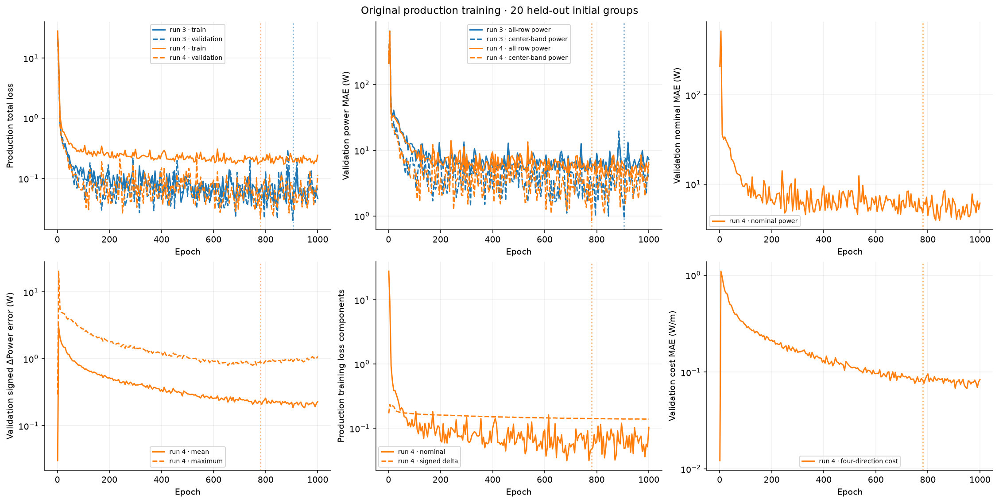

run,epoch,training_loss,validation_loss,power_mae,center_power_mae,center_sample_count,nominal_power_mae,delta_mae,delta_max_abs_error,delta_sign_threshold_w,delta_sign_count,delta_sign_accuracy,delta_by_direction,perturbation_cost_mae,training_nominal_loss,training_delta_loss
3,905,0.055379,0.020101,5.38223,0.922914,45,—,—,—,—,—,—,—,—,—,—
4,780,0.189297,0.0214662,4.74142,0.859273,45,4.72403,0.225926,0.905066,0.1,10,0.6,"{'ITM_plus': {'count': 20, 'delta_mae': 0.23902167817943493, 'sign_count': 2, 'sign_accuracy': 1.0}, 'ITM_minus': {'count': 20, 'delta_mae': 0.22294012864573923, 'sign_count': 2, 'sign_accuracy': 0.5}, 'ETM_plus': {'count': 20, 'delta_mae': 0.20117394207799996, 'sign_count': 3, 'sign_accuracy': 0.6666666666666666}, 'ETM_minus': {'count': 20, 'delta_mae': 0.24056781376957842, 'sign_count': 3, 'sign_accuracy': 0.3333333333333333}}",0.0832034,0.0471955,0.142101


In [11]:
production_history_dir = OUTPUTS_DIR / 'run4_training_audit'
production_history_path = production_history_dir / 'base_training_history.csv'
if not production_history_path.exists():
    production_history_path = production_history_dir / 'training_history.csv'
production_history = read_csv(production_history_path)
table(production_history, title='Original production base-training history', collapsed=True)
production_best_rows = []
if production_history:
    production_run_numbers = sorted({r['run'] for r in production_history})
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    for index, run_number in enumerate(production_run_numbers):
        history = sorted([r for r in production_history if r['run'] == run_number],
                         key=lambda row: row['epoch'])
        color, label = f'C{index % 10}', f'run {run_number}'
        epoch = values(history, 'epoch')
        monitored = [r for r in history if r.get('validation_loss') is not None]
        best = min(monitored, key=lambda r: r['validation_loss']) if monitored else None
        if best:
            production_best_rows.append(best)
        panels = [
            (axes[0, 0], [('training_loss', 'train', '-'),
                           ('validation_loss', 'validation', '--')], 'Production total loss'),
            (axes[0, 1], [('power_mae', 'all-row power', '-'),
                           ('center_power_mae', 'center-band power', '--')], 'Validation power MAE (W)'),
            (axes[0, 2], [('nominal_power_mae', 'nominal power', '-')], 'Validation nominal MAE (W)'),
            (axes[1, 0], [('delta_mae', 'mean', '-'),
                           ('delta_max_abs_error', 'maximum', '--')], 'Validation signed ΔPower error (W)'),
            (axes[1, 1], [('training_nominal_loss', 'nominal', '-'),
                           ('training_delta_loss', 'signed delta', '--')], 'Production training loss components'),
            (axes[1, 2], [('perturbation_cost_mae', 'four-direction cost', '-')], 'Validation cost MAE (W/m)'),
        ]
        for ax, fields, ylabel in panels:
            for field, component, style in fields:
                y = values(history, field)
                if np.isfinite(y).any():
                    ax.plot(epoch, y, style, color=color, label=f'{label} · {component}')
            if best and ax.lines:
                ax.axvline(best['epoch'], color=color, ls=':', alpha=0.55)
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
    for ax in axes.flat:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(fontsize=7)
        else:
            ax.text(0.5, 0.5, 'No saved diagnostic values', ha='center', va='center',
                    transform=ax.transAxes)
    fig.suptitle('Original production training · 20 held-out initial groups')
    show_figure(fig, 'production_base_training_run3_run4')
    table(production_best_rows, title='Lowest saved production validation-loss epoch per run')
else:
    display(Markdown('No saved production base-training history is available.'))


## Power, signed differences, and residuals

Each panel compares checkpoints evaluated on the same experiment and split. The
diagonal is exact agreement; residuals are **MLP − saved Finesse** values. Nominal
rows are excluded from difference plots so their identically zero differences do
not inflate agreement. Every saved prediction participates in these plots.


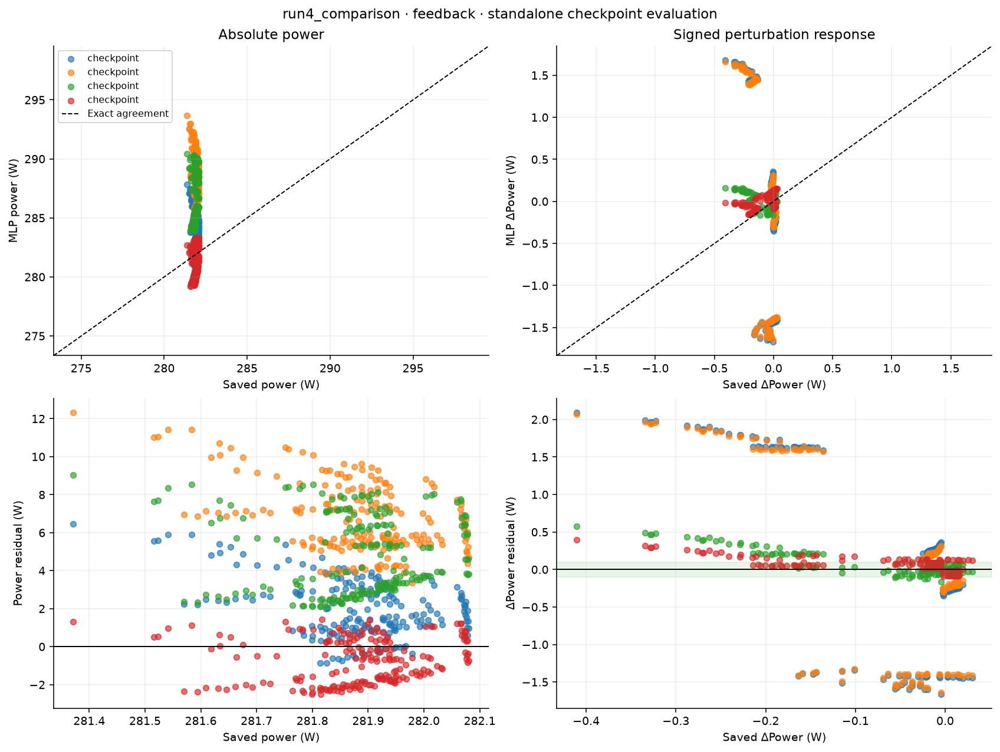

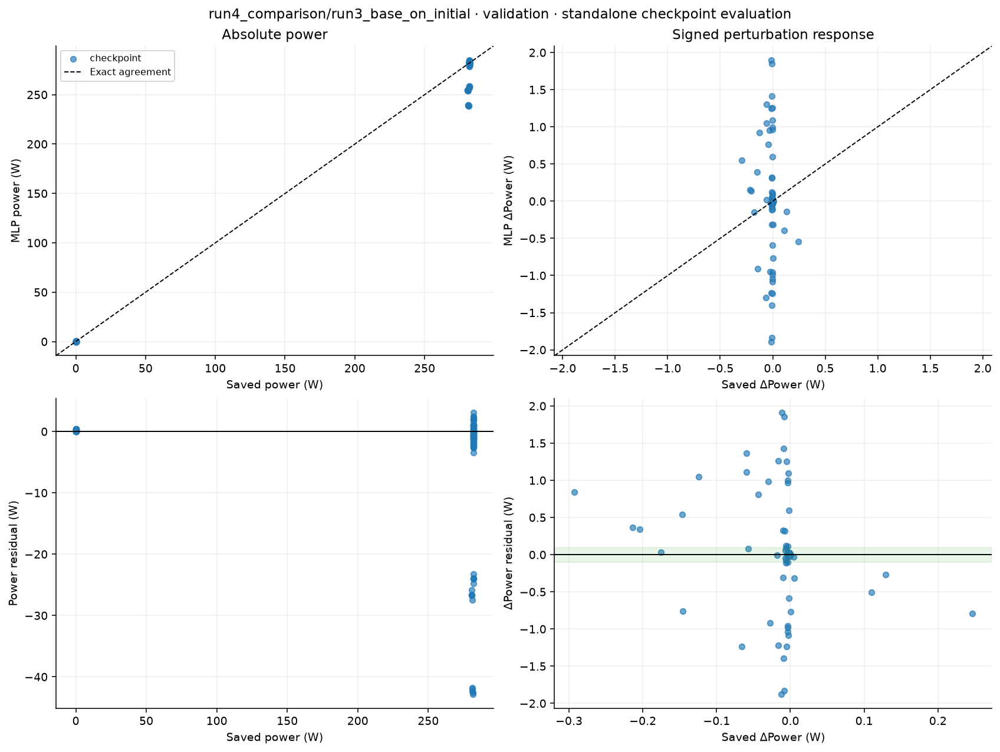

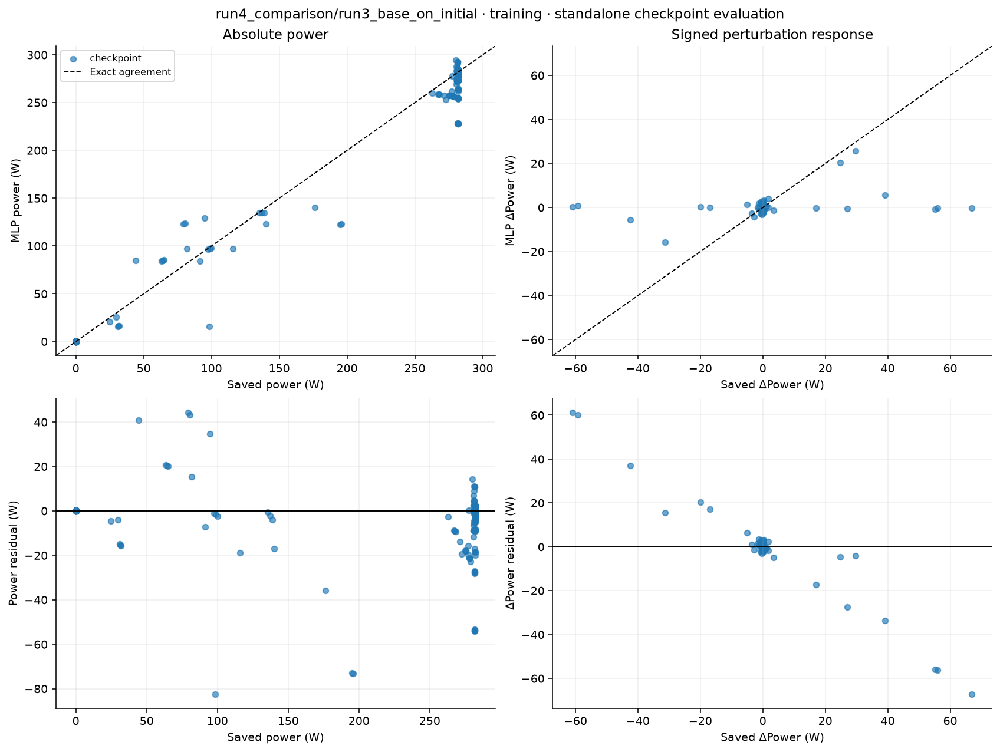

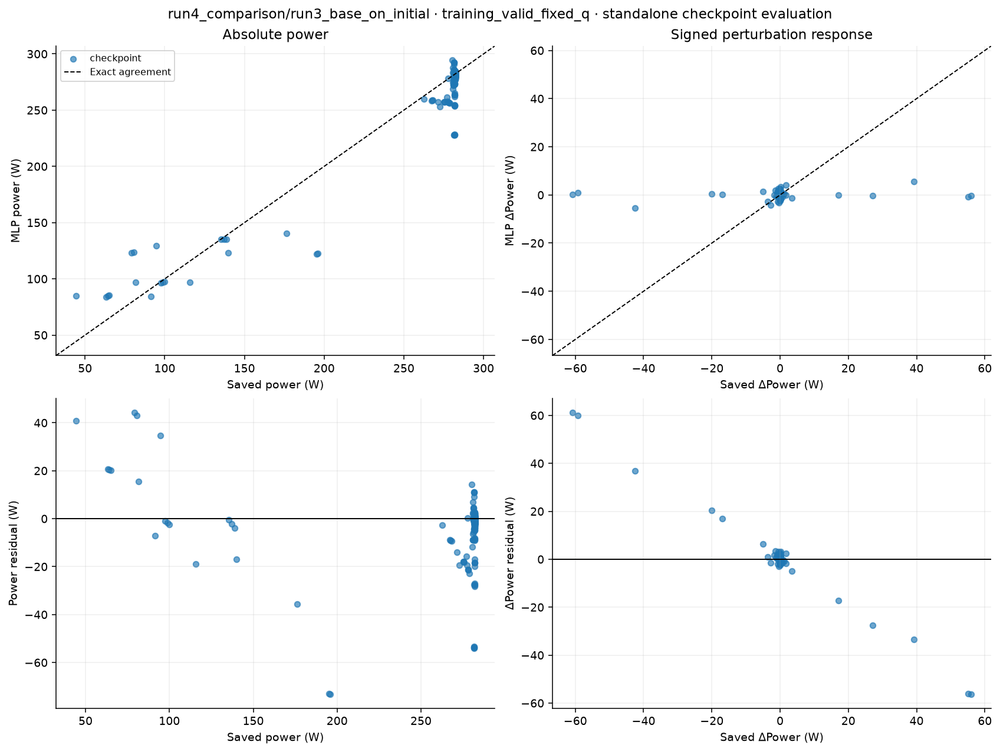

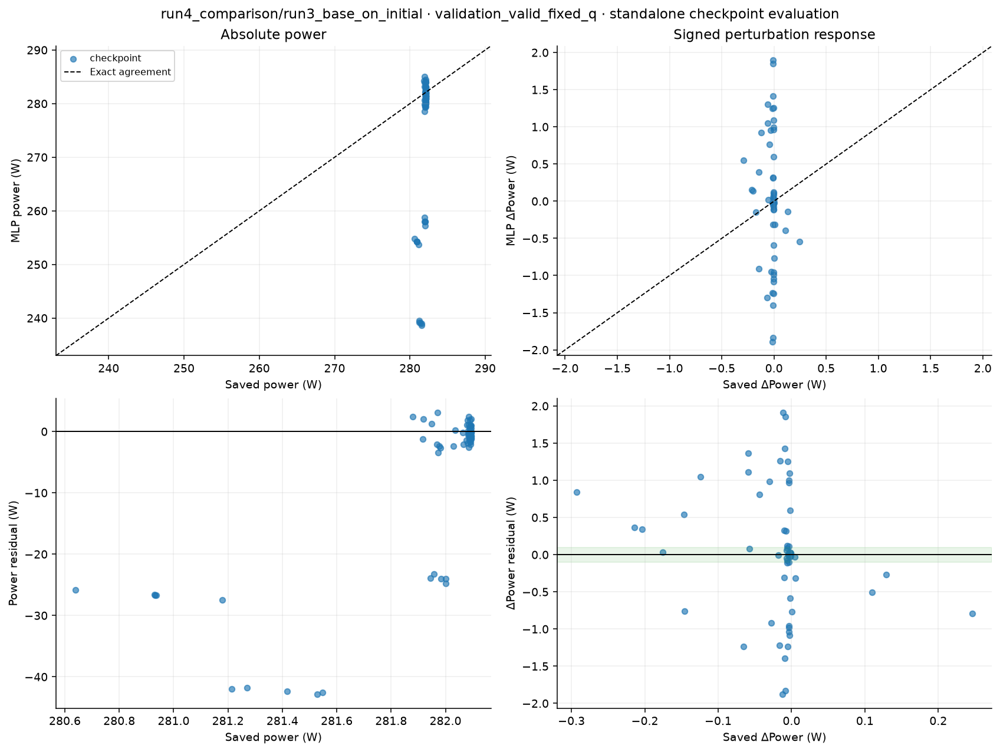

...

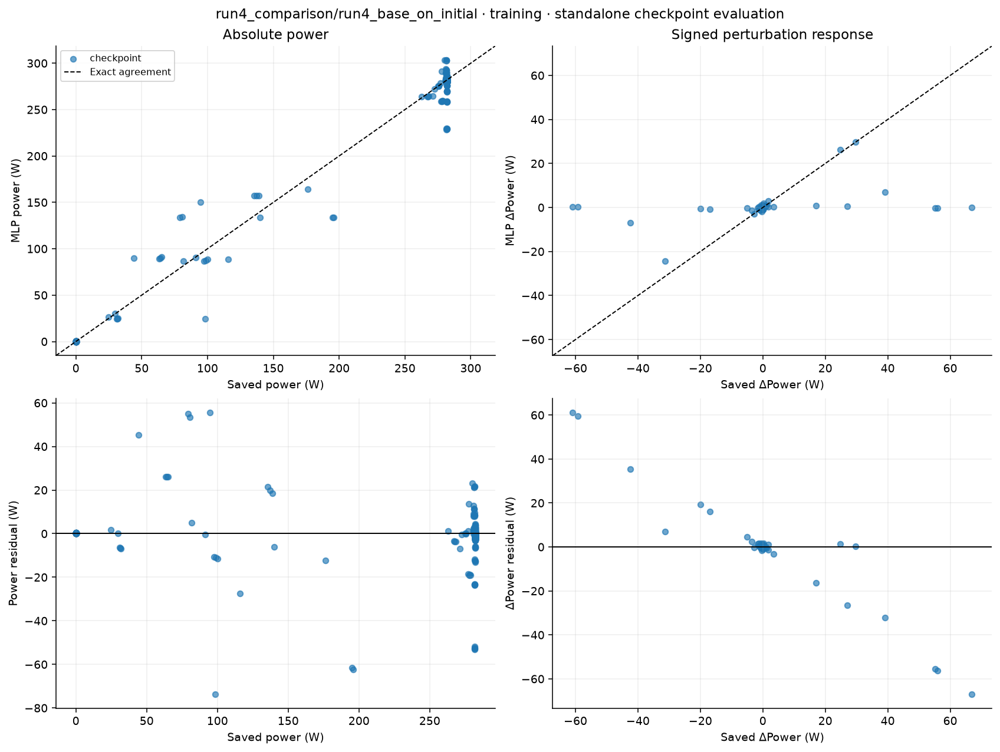

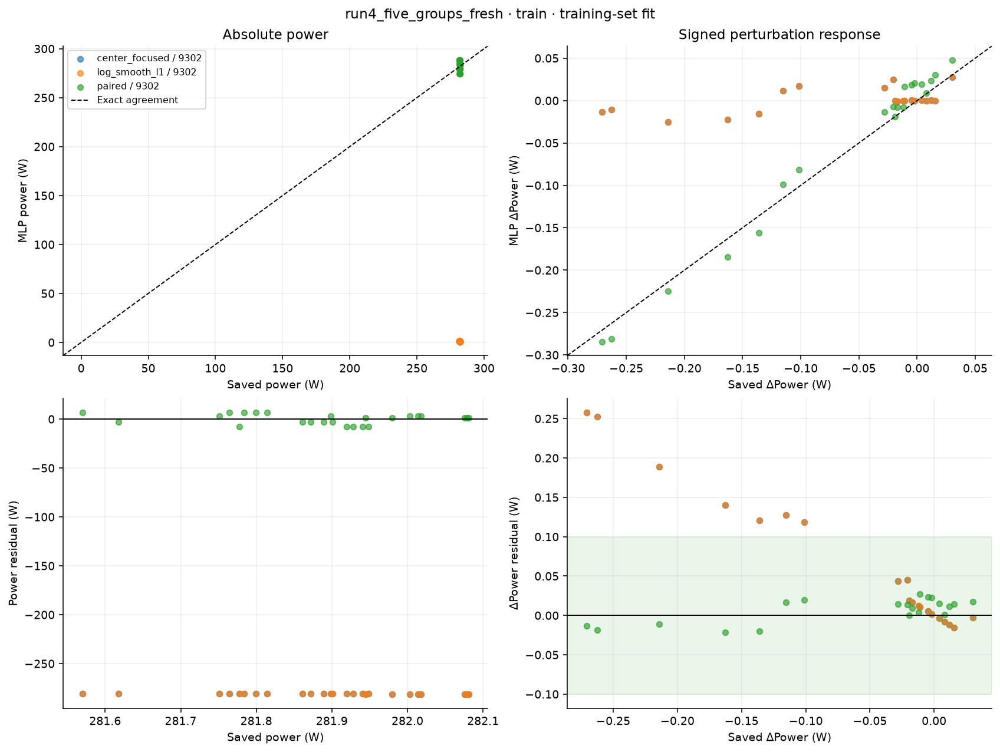

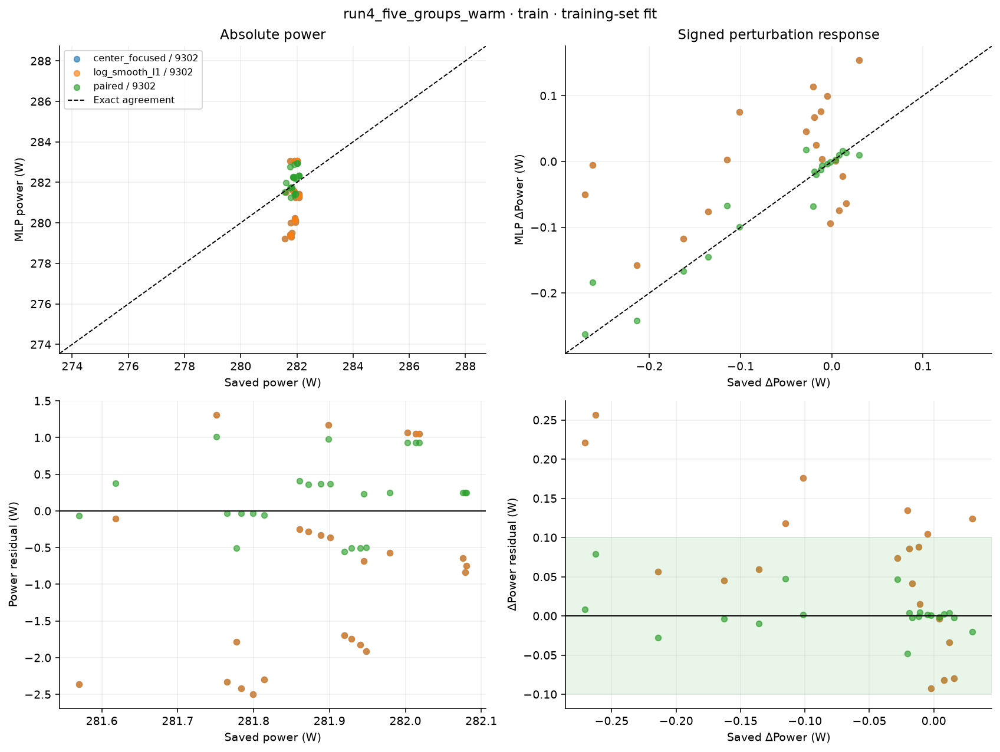

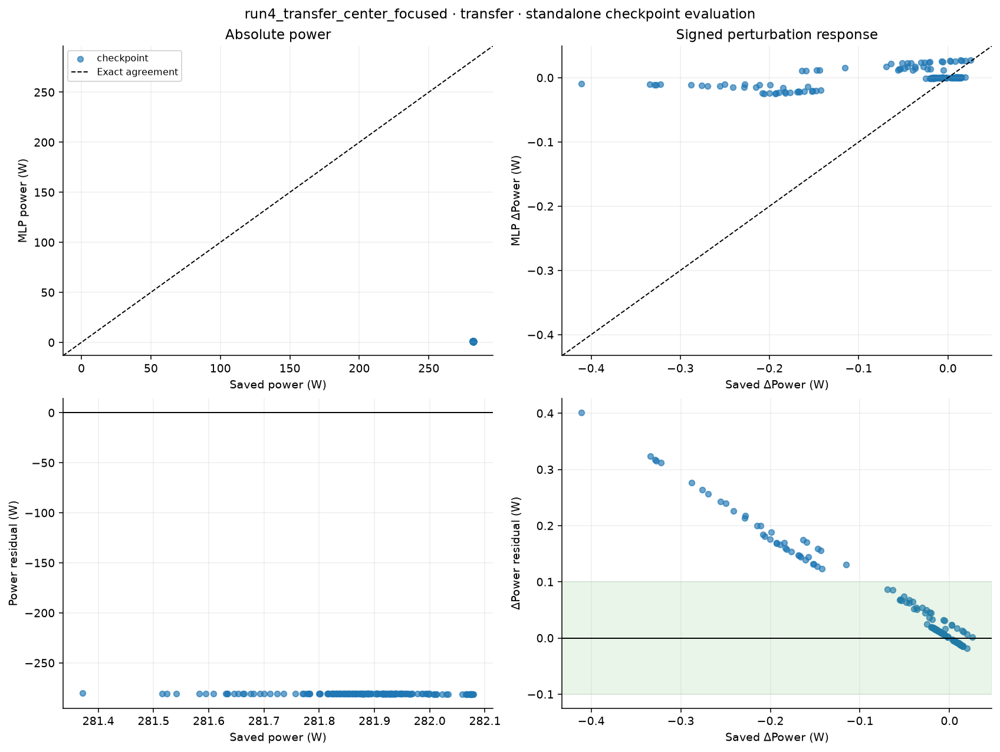

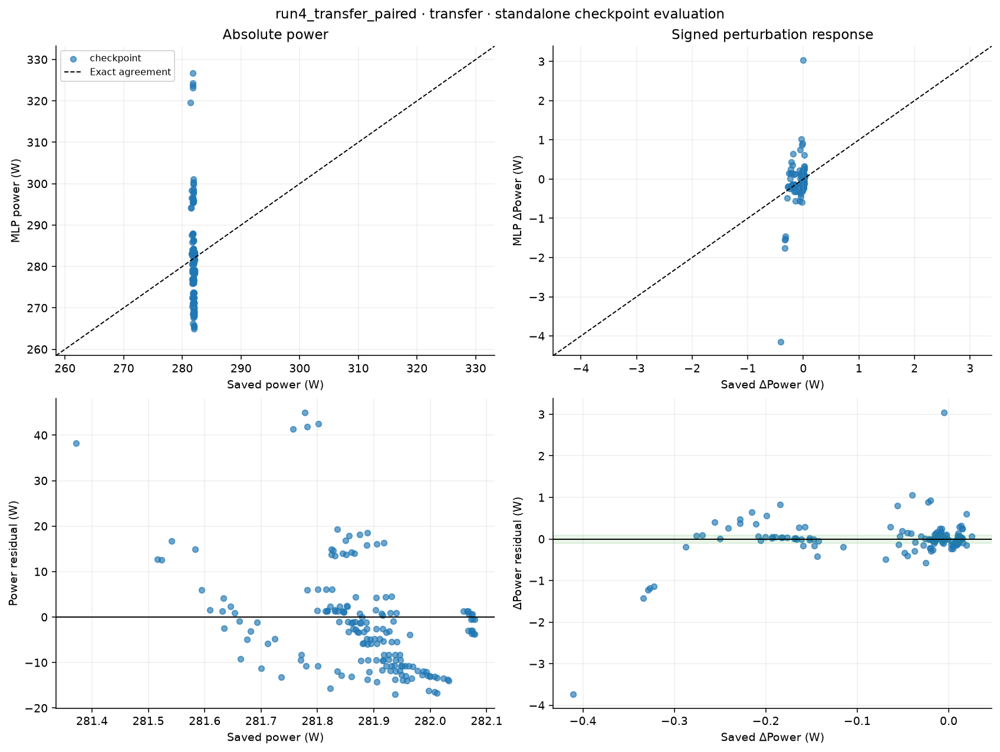

In [12]:
for experiment, split in comparison_keys:
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == experiment
                     and any(p['split'] == split for p in r['predictions'])]
    if not selected_runs:
        continue
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
    all_power_x, all_power_y, all_delta_x, all_delta_y = [], [], [], []
    for index, run in enumerate(selected_runs):
        rows = [r for r in run['predictions'] if r['split'] == split]
        paired = [r for r in rows if r['direction'] != 'nominal']
        label = run['tags']['variant'] + (f' / {run["tags"]["seed"]}' if run['tags']['seed'] is not None else '')
        color = f'C{index % 10}'
        px, py = values(rows, 'power'), values(rows, 'predicted_power')
        dx, dy = values(paired, 'delta_power'), values(paired, 'predicted_delta_power')
        axes[0, 0].scatter(px, py, color=color, label=label, alpha=0.65, s=24)
        axes[0, 1].scatter(dx, dy, color=color, label=label, alpha=0.65, s=24)
        axes[1, 0].scatter(px, values(rows, 'power_error'), color=color, alpha=0.65, s=24)
        axes[1, 1].scatter(dx, values(paired, 'delta_error'), color=color, alpha=0.65, s=24)
        all_power_x.extend(px); all_power_y.extend(py)
        all_delta_x.extend(dx); all_delta_y.extend(dy)
    parity_line(axes[0, 0], all_power_x, all_power_y)
    parity_line(axes[0, 1], all_delta_x, all_delta_y)
    axes[0, 0].set(xlabel='Saved power (W)', ylabel='MLP power (W)', title='Absolute power')
    axes[0, 1].set(xlabel='Saved ΔPower (W)', ylabel='MLP ΔPower (W)', title='Signed perturbation response')
    axes[1, 0].set(xlabel='Saved power (W)', ylabel='Power residual (W)')
    axes[1, 1].set(xlabel='Saved ΔPower (W)', ylabel='ΔPower residual (W)')
    for ax in axes[1]:
        ax.axhline(0, color='black', lw=1)
    axes[1, 1].axhspan(-DELTA_ERROR_TARGET_W, DELTA_ERROR_TARGET_W, color='tab:green', alpha=0.1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {experiments[experiment]["scope"]}')
    show_figure(fig, f'parity_residuals_{experiment}_{split}')


## Four-direction perturbation cost

The `costs.json` tables contain **sum |DeltaPower / DeltaROC|**, in W/m,
for complete five-point groups, including both runs' initial designs. The
plots here show the perturbation term. The run-comparison section separately
reconstructs weighted nominal and total production costs from saved settings.
Unscorable entries remain visible as missing values.


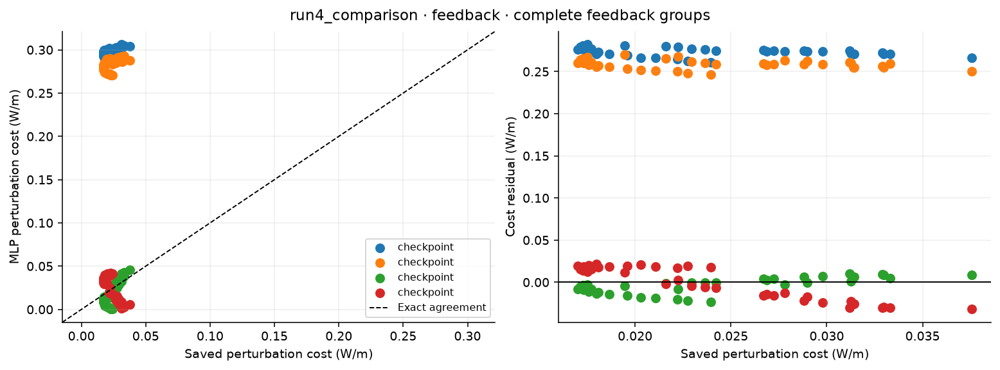

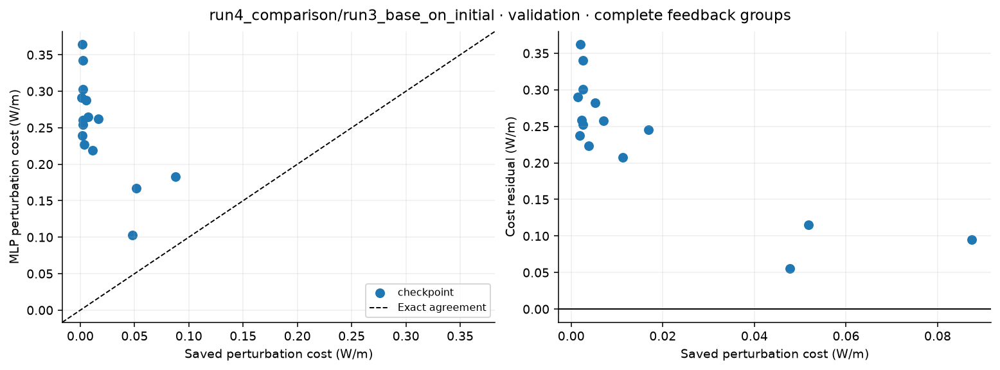

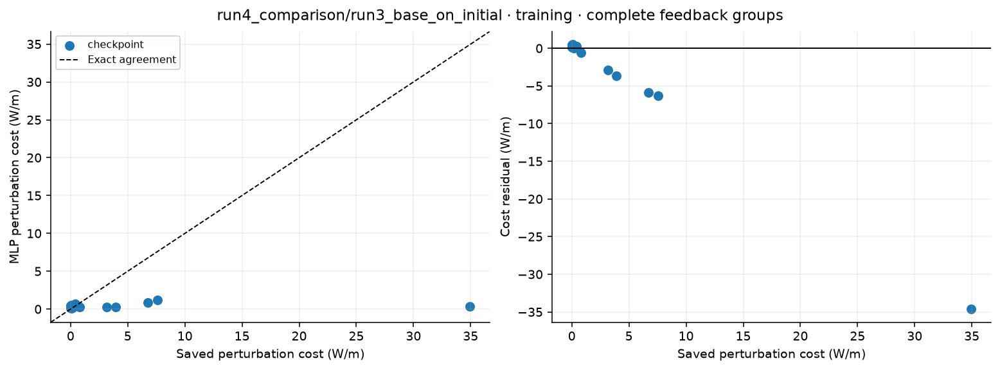

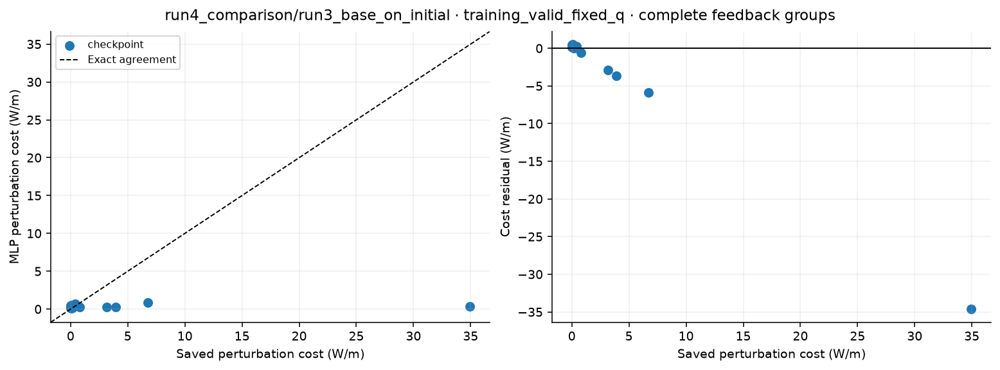

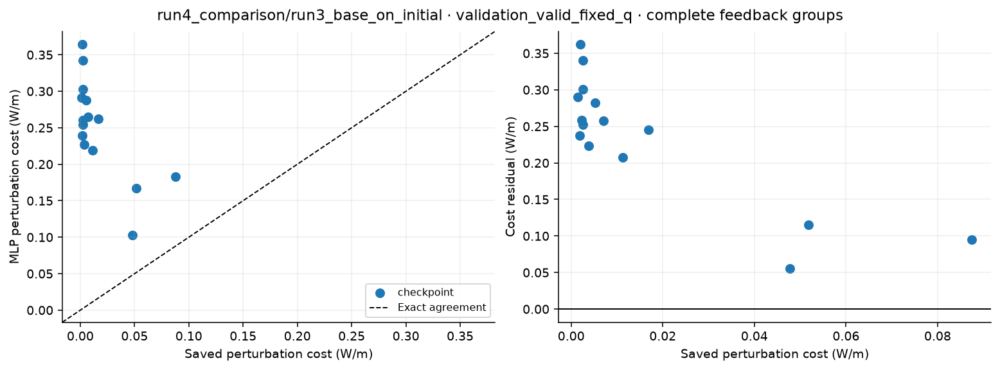

...

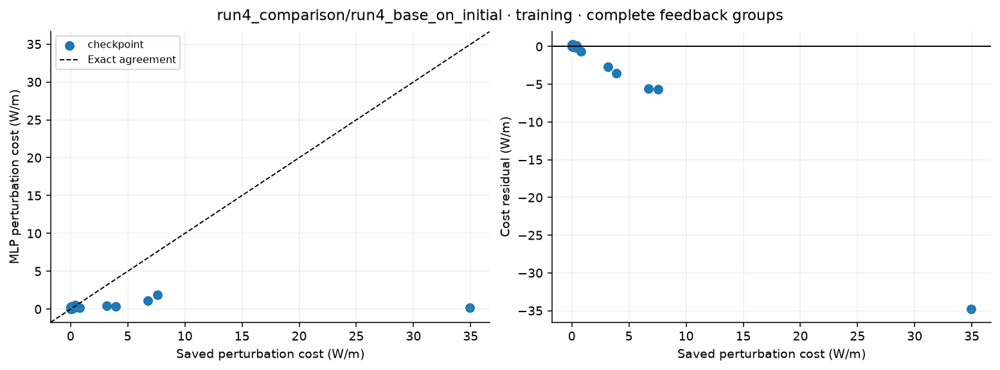

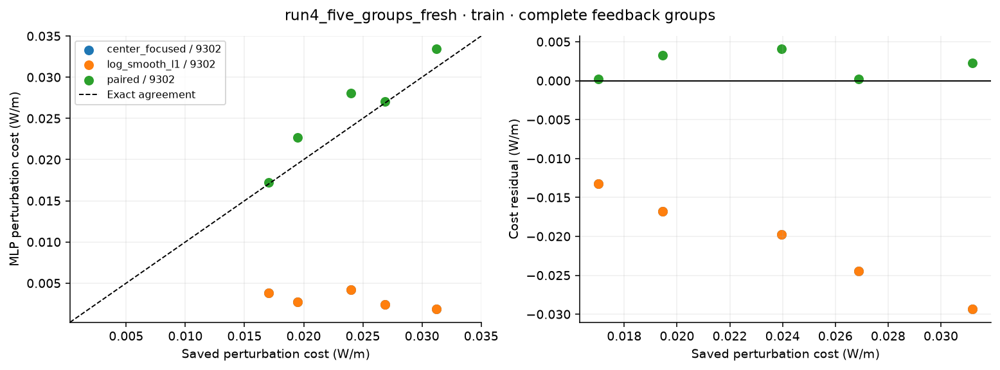

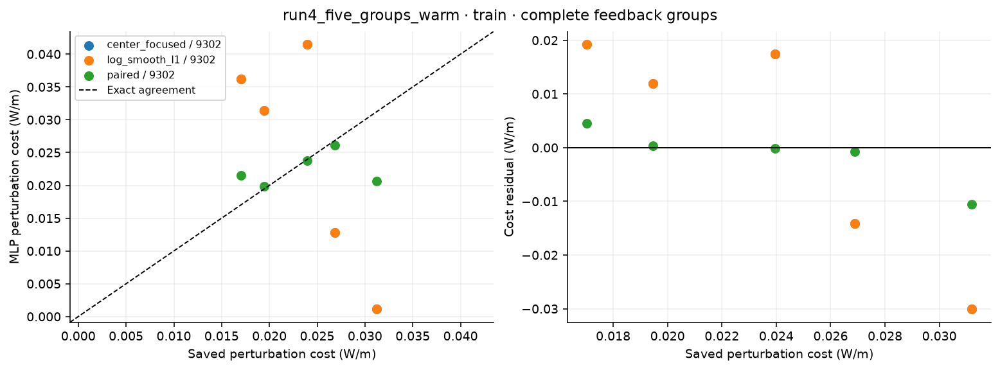

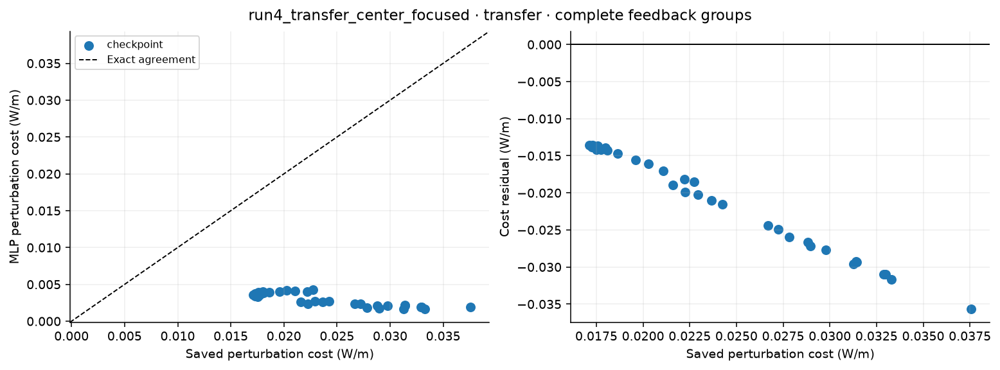

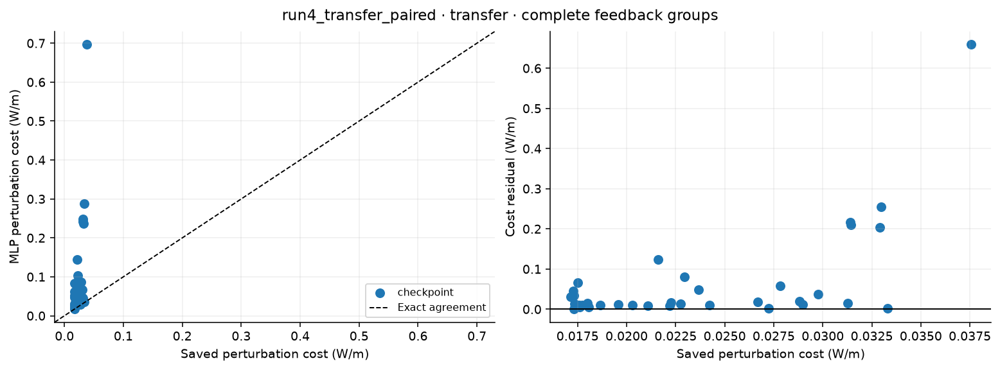

experiment,variant,seed,split,group_id,true_perturbation_cost,predicted_perturbation_cost,cost_error
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:0,0.00177108,0.276829,0.275058
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:1,0.0027184,0.255405,0.252687
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:2,0.172333,0.164026,-0.00830606
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:3,0.009514,0.350499,0.340985
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:5,—,5.48418e-05,—
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:6,0.0273209,0.401146,0.373825
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:7,0.00180921,0.320211,0.318402
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:8,0.0025199,0.256931,0.254411
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:9,0.00157644,0.263741,0.262165
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:12,0.00226453,0.253223,0.250958


In [13]:
for experiment, split in comparison_keys:
    rows = [r for r in cost_rows if r['experiment'] == experiment and r['split'] == split
            and r['cost_error'] is not None]
    if not rows:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    run_ids = list(dict.fromkeys(r['run_id'] for r in rows))
    for index, run_id in enumerate(run_ids):
        current = [r for r in rows if r['run_id'] == run_id]
        label = runs[run_id]['tags']['variant']
        if runs[run_id]['tags']['seed'] is not None:
            label += f' / {runs[run_id]["tags"]["seed"]}'
        axes[0].scatter(values(current, 'true_perturbation_cost'), values(current, 'predicted_perturbation_cost'), label=label, s=45)
        axes[1].scatter(values(current, 'true_perturbation_cost'), values(current, 'cost_error'), label=label, s=45)
    parity_line(axes[0], values(rows, 'true_perturbation_cost'), values(rows, 'predicted_perturbation_cost'))
    axes[0].set(xlabel='Saved perturbation cost (W/m)', ylabel='MLP perturbation cost (W/m)')
    axes[1].axhline(0, color='black', lw=1)
    axes[1].set(xlabel='Saved perturbation cost (W/m)', ylabel='Cost residual (W/m)')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · complete feedback groups')
    show_figure(fig, f'cost_{experiment}_{split}')
table(cost_rows, columns=['experiment', 'variant', 'seed', 'split', 'group_id',
    'true_perturbation_cost', 'predicted_perturbation_cost', 'cost_error'],
    title='All saved perturbation costs', collapsed=True)


## Inspect every five-point group

The complete group catalog below includes every saved five-point initial or feedback group.
Change `DETAIL_EXPERIMENT`, `DETAIL_SPLIT`, and `DETAIL_GROUP` in the setup cell, then
rerun the plotting cell. Set `SHOW_ALL_GROUP_RESPONSES = True` to plot the entire
catalog. `plot_group_response(experiment, split, group_id)` also works directly.

Each ITM or ETM curve connects only the three saved samples. It does not represent
a dense simulator sweep. Fixed input q combines geometry and mismatch effects;
one constant-q group's fit cannot establish learned q dependence.


In [14]:
feedback_catalog = []
grouped_predictions = defaultdict(list)
for row in predictions_rows:
    grouped_predictions[(row['experiment'], row['split'], row['group_id'])].append(row)
required_directions = set(DIRECTIONS[:5])
# A response panel must compare the same saved labels for every checkpoint.
for key, rows in grouped_predictions.items():
    references = {}
    for row in rows:
        references.setdefault(row['run_id'], {})[(row['source'], row['h5_key'])] = row['power']
    first = next(iter(references.values()))
    if any(reference != first for reference in references.values()):
        raise ValueError(f'Cannot combine different saved sample selections in group panel {key}.')
for (experiment, split, group_id), rows in sorted(grouped_predictions.items()):
    if not required_directions.issubset({r['direction'] for r in rows}):
        continue
    first_run = rows[0]['run_id']
    reference = [r for r in rows if r['run_id'] == first_run]
    nominal = next(r for r in reference if r['direction'] == 'nominal')
    paired = [r for r in reference if r['direction'] != 'nominal']
    feedback_catalog.append({'experiment': experiment, 'split': split, 'group_id': group_id,
        'nominal_power_W': nominal['power'], 'ITM_ROC_m': nominal['ITM_Rc'],
        'ETM_ROC_m': nominal['ETM_Rc'], 'q_real_m': nominal['q_input_real'],
        'q_imag_m': nominal['q_input_imag'], 'checkpoints': len({r['run_id'] for r in rows}),
        'min_true_delta_W': min(r['delta_power'] for r in paired),
        'max_true_delta_W': max(r['delta_power'] for r in paired)})
table(feedback_catalog, title='All complete five-point groups', collapsed=True)


def plot_group_response(experiment, split, group_id):
    rows = grouped_predictions.get((experiment, split, group_id), [])
    if not rows or not required_directions.issubset({r['direction'] for r in rows}):
        print('No complete feedback group matches these selectors. See feedback_catalog.')
        return
    run_ids = list(dict.fromkeys(r['run_id'] for r in rows))
    reference = [r for r in rows if r['run_id'] == run_ids[0]]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    for column, mirror in enumerate(['ITM', 'ETM']):
        field = f'delta_{mirror.lower()}_roc'
        points = sorted([r for r in reference if r['direction'] == 'nominal' or r['direction'].startswith(mirror)], key=lambda r: r[field])
        for ax, target, ylabel in zip(axes[:, column], ['power', 'delta_power'], ['Power (W)', 'Signed ΔPower (W)']):
            ax.plot(values(points, field), values(points, target), 'o--', color='black', lw=2, label='Saved Finesse samples')
            for index, run_id in enumerate(run_ids):
                predicted = sorted([r for r in rows if r['run_id'] == run_id and
                                    (r['direction'] == 'nominal' or r['direction'].startswith(mirror))], key=lambda r: r[field])
                tags = runs[run_id]['tags']
                label = Path(run_id).name if tags['variant'] == 'checkpoint' else (tags['variant'] + (f' / {tags["seed"]}' if tags['seed'] is not None else ''))
                ax.plot(values(predicted, field), values(predicted, f'predicted_{target}'), 'o--', color=f'C{index % 10}', label=label)
            ax.set(xlabel=f'Δ{mirror} ROC (m)', ylabel=ylabel)
        axes[0, column].set_title(mirror)
        axes[1, column].axhline(0, color='grey', lw=1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {group_id} · fixed input q\nLines connect sampled points')
    show_figure(fig, f'response_{experiment}_{split}_{group_id}')
    table(rows, columns=['run_id', 'variant', 'seed', 'direction', 'delta_itm_roc', 'delta_etm_roc',
          'power', 'predicted_power', 'power_error', 'delta_power', 'predicted_delta_power', 'delta_error'],
          title=f'{group_id}: every sampled response', collapsed=True)


experiment,split,group_id,nominal_power_W,ITM_ROC_m,ETM_ROC_m,q_real_m,q_imag_m,checkpoints,min_true_delta_W,max_true_delta_W
run4_comparison,feedback,round:10:0,281.94,-2575.36,3788.52,-506.227,1023.45,4,-0.162857,0.00804129
run4_comparison,feedback,round:11:0,281.894,-2534.34,3787.13,-496.695,1006.03,4,-0.183124,0.010495
run4_comparison,feedback,round:12:0,281.938,-2579.56,3790,-504.363,1023.06,4,-0.166125,0.0082179
run4_comparison,feedback,round:13:0,281.939,-2590.76,3792.33,-502.811,1024.62,4,-0.168769,0.00820456
run4_comparison,feedback,round:14:0,281.961,-2623.82,3795.12,-507.193,1036.12,4,-0.160922,0.00695197
run4_comparison,feedback,round:15:0,281.948,-2610.63,3794.99,-503.264,1029.84,4,-0.167748,0.007731
run4_comparison,feedback,round:16:0,281.987,-2668.22,3798.9,-513.337,1051.75,4,-0.152275,0.00546165
run4_comparison,feedback,round:17:0,281.995,-2689.26,3801.62,-514.222,1057.57,4,-0.151946,0.00503978
run4_comparison,feedback,round:18:0,282.008,-2716.7,3803.89,-518.449,1067.56,4,-0.147679,0.00422735
run4_comparison,feedback,round:19:0,282.03,-2781.64,3810.12,-527.043,1090.08,4,-0.142611,0.00269175


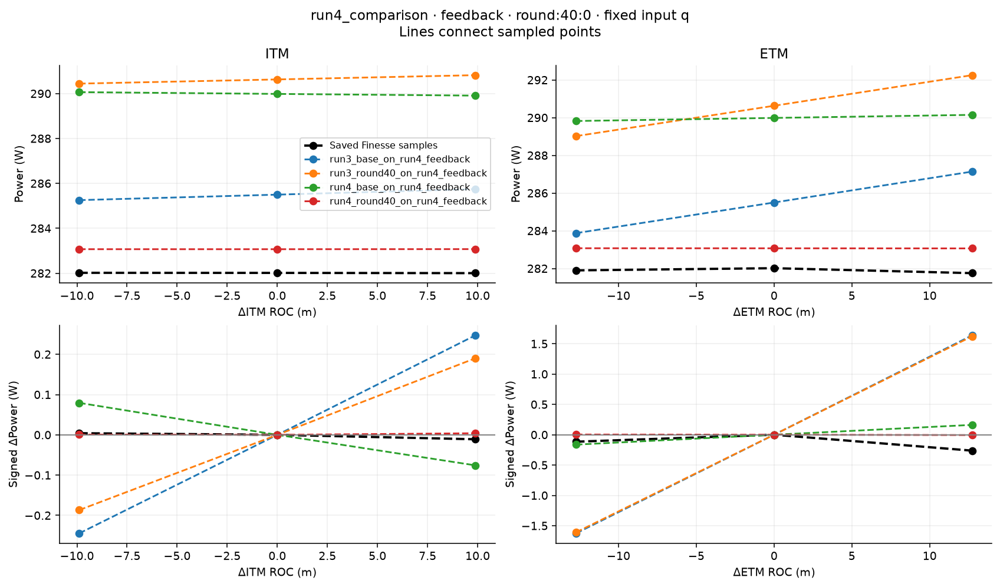

run_id,variant,seed,direction,delta_itm_roc,delta_etm_roc,power,predicted_power,power_error,delta_power,predicted_delta_power,delta_error
run4_comparison/run3_base_on_run4_feedback,checkpoint,—,nominal,0,0,282.014,285.499,3.48501,0,0,0
run4_comparison/run3_base_on_run4_feedback,checkpoint,—,ITM_plus,9.88477,0,282.003,285.746,3.74308,-0.0109718,0.247103,0.258075
run4_comparison/run3_base_on_run4_feedback,checkpoint,—,ITM_minus,-9.88501,0,282.018,285.254,3.23636,0.00407539,-0.24457,-0.248645
run4_comparison/run3_base_on_run4_feedback,checkpoint,—,ETM_plus,0,12.7302,281.751,287.137,5.38602,-0.262587,1.63843,1.90101
run4_comparison/run3_base_on_run4_feedback,checkpoint,—,ETM_minus,0,-12.7302,281.899,283.873,1.97435,-0.115191,-1.62585,-1.51066
run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,nominal,0,0,282.014,290.629,8.61501,0,0,0
run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,ITM_plus,9.88477,0,282.003,290.819,8.81613,-0.0109718,0.190156,0.201128
run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,ITM_minus,-9.88501,0,282.018,290.442,8.42423,0.00407539,-0.186697,-0.190772
run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,ETM_plus,0,12.7302,281.751,292.252,10.5007,-0.262587,1.62315,1.88574
run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,ETM_minus,0,-12.7302,281.899,289.02,7.12101,-0.115191,-1.60919,-1.494


In [15]:
if SHOW_ALL_GROUP_RESPONSES:
    for group in feedback_catalog:
        plot_group_response(group['experiment'], group['split'], group['group_id'])
elif feedback_catalog:
    key = (DETAIL_EXPERIMENT, DETAIL_SPLIT, DETAIL_GROUP)
    available = {(g['experiment'], g['split'], g['group_id']) for g in feedback_catalog}
    if key not in available:
        first = feedback_catalog[0]
        key = (first['experiment'], first['split'], first['group_id'])
        print(f'Configured group unavailable; showing {key}.')
    plot_group_response(*key)
else:
    print('No complete feedback groups saved in the selected experiments.')


## Largest errors and diagnostic checks

The worst sample rows are selected separately for each checkpoint and split, so an
experiment with much larger errors cannot hide failures in another experiment.
The configurable 0.1 W difference-error target is a diagnostic aid for multi-watt
responses, rather than a production acceptance criterion. Both mean and maximum
errors are shown; sign failures and checkpoints selected at the epoch budget are
called out for inspection.


In [16]:
worst_rows, diagnostic_rows = [], []
for row in metric_rows:
    paired = [p for p in runs[row['run_id']]['predictions']
              if p['split'] == row['split'] and p['direction'] != 'nominal']
    worst_rows.extend(sorted(paired, key=lambda p: abs(p['delta_error']), reverse=True)[:TOP_ERRORS_PER_RUN_SPLIT])
    budget = runs[row['run_id']]['config'].get('epochs')
    flags = []
    if row.get('delta_mae', 0) > DELTA_ERROR_TARGET_W:
        flags.append('mean Δ error exceeds target')
    if row.get('delta_max_abs_error', 0) > DELTA_ERROR_TARGET_W:
        flags.append('maximum Δ error exceeds target')
    if row.get('sign_count', 0) == 0:
        flags.append('no significant differences for sign check')
    elif row.get('sign_accuracy') is not None and row['sign_accuracy'] < 1:
        flags.append('some significant Δ signs are wrong')
    if row.get('best_epoch') is not None and budget is not None and row['best_epoch'] == budget:
        flags.append('selected checkpoint is at epoch budget')
    if 'smoke' in row['experiment'].lower():
        flags.append('smoke run: workflow check only')
    diagnostic_rows.append({'experiment': row['experiment'], 'variant': row['variant'],
        'seed': row['seed'], 'split': row['split'], 'scope': row['scope'],
        'checks': '; '.join(flags) or 'within configured Δ error target; inspect context'})
table(worst_rows, columns=['experiment', 'variant', 'seed', 'split', 'group_id', 'h5_key',
    'direction', 'nominal_power', 'power', 'predicted_power', 'power_error',
    'delta_power', 'predicted_delta_power', 'delta_error'],
    title=f'Largest {TOP_ERRORS_PER_RUN_SPLIT} difference errors per checkpoint / split')
table(diagnostic_rows, title='Checks derived from saved metrics')


experiment,variant,seed,split,group_id,h5_key,direction,nominal_power,power,predicted_power,power_error,delta_power,predicted_delta_power,delta_error
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:56,sim_284,ETM_minus,31.3778,98.3458,15.9287,-82.4172,66.968,-0.202082,-67.1701
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:59,sim_299,ETM_minus,139.956,79.0659,123.288,44.2224,-60.8899,0.26144,61.1513
run4_comparison/run3_base_on_initial,checkpoint,—,training,base:59,sim_296,ITM_plus,139.956,80.6803,123.832,43.1521,-59.2754,0.805616,60.0811
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,base:59,sim_299,ETM_minus,139.956,79.0659,123.288,44.2224,-60.8899,0.26144,61.1513
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,base:59,sim_296,ITM_plus,139.956,80.6803,123.832,43.1521,-59.2754,0.805616,60.0811
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,base:59,sim_298,ETM_plus,139.956,195.961,122.764,-73.1971,56.0056,-0.262602,-56.2682
run4_comparison/run3_base_on_initial,checkpoint,—,validation,base:90,sim_451,ITM_plus,282.093,282.081,283.938,1.85687,-0.0119267,1.89826,1.91019
run4_comparison/run3_base_on_initial,checkpoint,—,validation,base:90,sim_452,ITM_minus,282.093,282.081,280.151,-1.92947,-0.0125461,-1.8887,-1.87615
run4_comparison/run3_base_on_initial,checkpoint,—,validation,base:68,sim_341,ITM_plus,282.093,282.085,283.158,1.07309,-0.00805406,1.84703,1.85509
run4_comparison/run3_base_on_initial,checkpoint,—,validation_valid_fixed_q,base:90,sim_451,ITM_plus,282.093,282.081,283.938,1.85687,-0.0119267,1.89826,1.91019


experiment,variant,seed,split,scope,checks
run4_comparison/run3_base_on_initial,checkpoint,—,training,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run3_base_on_initial,checkpoint,—,training_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run3_base_on_initial,checkpoint,—,validation,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run3_base_on_initial,checkpoint,—,validation_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison,checkpoint,—,feedback,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison,checkpoint,—,feedback,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run4_base_on_initial,checkpoint,—,training,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run4_base_on_initial,checkpoint,—,training_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run4_base_on_initial,checkpoint,—,validation,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
run4_comparison/run4_base_on_initial,checkpoint,—,validation_valid_fixed_q,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong


In [17]:
findings = []
for name, record in audits.items():
    audit = record['audit']
    findings.append(f'**{name}:** {audit["rows"]} samples in {audit["groups"]} groups; '
                    f'{audit["valid_fixed_q_groups"]} valid fixed-q groups, '
                    f'{audit["zero_output_rows"]} zero-output rows.')
    check = audit.get('inference_check')
    if check:
        findings.append(f'**{name} feature check:** {check["rows"] - check["mismatches"]}/{check["rows"]} '
                        'saved rows agree with the documented tolerances.')
for name, experiment in experiments.items():
    selected = [r for r in metric_rows if r['experiment'] == name]
    if experiment['scope'] == 'training-set fit':
        train = [r for r in selected if r['split'] == 'train']
        best = min(train, key=lambda r: r['delta_mae']) if train else None
        if best:
            findings.append(f'**{name}:** lowest saved training ΔPower MAE is {best["delta_mae"]:.6g} W '
                            f'({best["variant"]}, seed {best["seed"]}); maximum error is '
                            f'{best["delta_max_abs_error"]:.6g} W. This measures training reconstruction.')
    elif experiment['scope'] == 'generalization smoke run':
        findings.append(f'**{name}:** {experiment["config"].get("epochs")} epochs; '
                        'these held-out tables validate the workflow and do not establish trained model quality.')
    elif experiment['scope'] == 'standalone checkpoint evaluation':
        findings.append(f'**{name}:** existing-model predictions are included; independence from its '
                        'prior training is not established by these saved artifacts.')
    else:
        findings.append(f'**{name}:** checkpoints were monitored on '
                        f'{selected[0].get("monitor_split") if selected else "unspecified"}; '
                        'use validation for choices and preserve the test holdout.')
display(Markdown('\n\n'.join('- ' + finding for finding in findings) or 'No saved findings available.'))


- **run4_audit:** 700 samples in 140 groups; 118 valid fixed-q groups, 104 zero-output rows.

- **run4_selected_feature_audit:** 25 samples in 5 groups; 5 valid fixed-q groups, 0 zero-output rows.

- **run4_selected_feature_audit feature check:** 25/25 saved rows agree with the documented tolerances.

- **run4_comparison/run3_base_on_initial:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run4_comparison:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run4_comparison/run4_base_on_initial:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run4_five_groups_fresh:** lowest saved training ΔPower MAE is 0.0147322 W (paired, seed 9302); maximum error is 0.0273339 W. This measures training reconstruction.

- **run4_five_groups_warm:** lowest saved training ΔPower MAE is 0.015795 W (paired, seed 9302); maximum error is 0.079187 W. This measures training reconstruction.

- **run4_transfer_center_focused:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **run4_transfer_paired:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

## Full records, configurations, and provenance

Expand a panel to view every saved sample, prediction, or history row and the exact
configuration and source hashes. Nothing in these tables is silently truncated.
The optional saved-figure gallery displays existing PNG artifacts without replacing
them. Checkpoint binaries remain listed in the artifact inventory.


In [18]:
for name, record in audits.items():
    json_panel(f'{name}: audit.json', record['audit'])
    json_panel(f'{name}: config.json', record['config'])
    table(record['samples'], title=f'{name}: all sample records', collapsed=True)
for name, experiment in experiments.items():
    json_panel(f'{name}: config.json', experiment['config'])
    if experiment['provenance']:
        json_panel(f'{name}: provenance.json (groups, exclusions, scales, hashes)', experiment['provenance'])
    summary = read_csv(experiment['path'] / 'summary.csv')
    if summary:
        table(summary, title=f'{name}: saved summary.csv', collapsed=True)
for run_id, run in runs.items():
    json_panel(f'{run_id}: metrics.json', run['metrics'])
    json_panel(f'{run_id}: resolved run config.json', run['config'])
    table(run['predictions'], title=f'{run_id}: all predictions', collapsed=True)
    if run['history']:
        table(run['history'], title=f'{run_id}: full training history', collapsed=True)


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_0,nominal,-2337.62,3194.95,-1300.15,1161.41,282.094,282.094,0,0,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_1,ITM_plus,-2329.91,3194.95,-1300.15,1161.41,282.092,282.094,-0.00165064,7.71411,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_2,ITM_minus,-2345.34,3194.95,-1300.15,1161.41,282.092,282.094,-0.00164766,-7.71411,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_3,ETM_plus,-2337.62,3205.5,-1300.15,1161.41,282.087,282.094,-0.00712851,0,10.5432,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_4,ETM_minus,-2337.62,3184.41,-1300.15,1161.41,282.087,282.094,-0.0070364,0,-10.5435,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_5,nominal,-3458.16,2917.84,-2666.3,1453.05,282.094,282.094,0,0,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_6,ITM_plus,-3446.75,2917.84,-2666.3,1453.05,282.082,282.094,-0.0117895,11.4121,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_7,ITM_minus,-3469.58,2917.84,-2666.3,1453.05,282.082,282.094,-0.012185,-11.4119,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_8,ETM_plus,-3458.16,2927.47,-2666.3,1453.05,282.091,282.094,-0.00298796,0,9.62891,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_9,ETM_minus,-3458.16,2908.21,-2666.3,1453.05,282.091,282.094,-0.00295886,0,-9.62891,False,True


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True


comparison,run,checkpoint,split,groups,rows,power_mae,nominal_power_mae,delta_mae,sign_count,sign_correct,sign_accuracy,perturbation_cost_mae,full_cost_mae,predicted_full_cost_mean,true_full_cost_mean,interpretation
original_online_own_selected_points,3,base for round1; roundN-1 for roundN,online,40,200,17.8715,11.3952,9.92912,131,48,0.366412,5.9183,2.95993,0.0423476,2.9962,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
original_online_own_selected_points,4,base for round1; roundN-1 for roundN,online,40,200,2.38966,2.35021,0.0723349,47,32,0.680851,0.0229941,0.01151,0.00214655,0.0136565,Each run chose its own geometries. These are original predictions before that round's Finesse feedback; not a controlled comparison of architectures.
same_target_feedback_geometries,3,base,feedback,40,200,2.13289,2.00188,0.935642,47,7,0.148936,0.273561,0.136768,0.150425,0.0136565,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,3,round40,feedback,40,200,6.76059,6.70426,0.898612,47,7,0.148936,0.258706,0.129312,0.142968,0.0136565,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
own_initial_checkpoint_split,3,base,training,80,400,4.57823,3.63174,2.0875,48,26,0.541667,1.09304,0.546319,0.164908,0.46105,"Training fit, including all rows production trained."
own_initial_checkpoint_split,3,base,training_valid_fixed_q,63,315,5.35676,4.347,2.28532,42,21,0.5,1.0099,0.504985,0.157196,0.408034,"Training fit, including all rows production trained. Only valid fixed-q groups; overlaps corresponding all-row split."
own_initial_checkpoint_split,3,base,validation,20,100,5.38223,5.25234,0.481991,10,2,0.2,0.23489,0.117491,0.12748,0.00998867,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test.
own_initial_checkpoint_split,3,base,validation_valid_fixed_q,15,75,7.12385,6.95065,0.642019,10,2,0.2,0.23489,0.117491,0.12748,0.00998867,Whole-design validation labels were held out from weight updates but used for checkpoint selection; not an independent test. Only valid fixed-q groups; overlaps corresponding all-row split.
same_target_feedback_geometries,4,base,feedback,40,200,4.87073,4.81719,0.103184,47,9,0.191489,0.00807261,0.00403703,0.0115779,0.0136565,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.
same_target_feedback_geometries,4,round40,feedback,40,200,1.18294,1.18942,0.0934732,47,40,0.851064,0.0178189,0.00891597,0.0134223,0.0136565,"Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization."


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,0,5,25,280.94,281.219,20,0.0700343,0.257552,7,0.714286,0.1,5,0,0.0207139
log_smooth_l1,9302,train,0,5,25,280.94,281.219,20,0.0700343,0.257552,7,0.714286,0.1,5,0,0.0207139
paired,9302,train,1850,5,25,4.17671,7.52533,20,0.0147322,0.0273339,7,1,0.1,5,0,0.00199808


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,0,5,25,1.25328,2.49896,20,0.0946254,0.256763,7,0.714286,0.1,5,0,0.018555
log_smooth_l1,9302,train,0,5,25,1.25328,2.49896,20,0.0946254,0.256763,7,0.714286,0.1,5,0,0.018555
paired,9302,train,1750,5,25,0.426908,1.00829,20,0.015795,0.079187,7,1,0.1,5,0,0.00326609


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,training_exposure,evaluation_role,experiment,run_id,variant,seed,detector,scope
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_0,nominal,-2337.62,3194.95,-1300.15,1161.41,282.094,282.094,0,0,0,False,True,280.881,-1.21264,0,0,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_1,ITM_plus,-2329.91,3194.95,-1300.15,1161.41,282.092,282.094,-0.00165064,7.71411,0,False,True,281.673,-0.419943,0.791045,0.792695,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_2,ITM_minus,-2345.34,3194.95,-1300.15,1161.41,282.092,282.094,-0.00164766,-7.71411,0,False,True,280.094,-1.99821,-0.787222,-0.785575,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_3,ETM_plus,-2337.62,3205.5,-1300.15,1161.41,282.087,282.094,-0.00712851,0,10.5432,False,True,281.264,-0.822849,0.38266,0.389789,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_4,ETM_minus,-2337.62,3184.41,-1300.15,1161.41,282.087,282.094,-0.0070364,0,-10.5435,False,True,280.503,-1.58452,-0.37892,-0.371884,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_5,nominal,-3458.16,2917.84,-2666.3,1453.05,282.094,282.094,0,0,0,False,True,282.952,0.857599,0,0,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_6,ITM_plus,-3446.75,2917.84,-2666.3,1453.05,282.082,282.094,-0.0117895,11.4121,0,False,True,284.364,2.28171,1.41232,1.42411,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_7,ITM_minus,-3469.58,2917.84,-2666.3,1453.05,282.082,282.094,-0.012185,-11.4119,0,False,True,281.551,-0.5307,-1.40048,-1.3883,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,sim_8,ETM_plus,-3458.16,2927.47,-2666.3,1453.05,282.091,282.094,-0.00298796,0,9.62891,False,True,282.909,0.817533,-0.0430535,-0.0400656,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run3_base_on_initial,run4_comparison/run3_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run3/base_500.h5,si

split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,training_exposure,evaluation_role,experiment,run_id,variant,seed,detector,scope
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,282.377,0.592862,0,0,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,282.605,0.839958,0.227912,0.247096,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,282.15,0.350173,-0.227053,-0.242689,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,283.801,2.23083,1.42386,1.63797,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,280.964,-0.850184,-1.41298,-1.44305,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_0,nominal,-2453.45,3776.22,-495.549,985.005,281.839,281.839,0,0,0,False,True,282.543,0.703936,0,0,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_compariso

split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,training_exposure,evaluation_role,experiment,run_id,variant,seed,detector,scope
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,287.136,5.35256,0,0,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,287.329,5.56403,0.192279,0.211463,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,286.947,5.14711,-0.189816,-0.205452,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,288.528,6.95866,1.39199,1.6061,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,285.757,3.9428,-1.3797,-1.40977,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run3_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_0,nominal,-2453.45,3776.22,-495.549,985.005,281.839,281.839,0,0,0,False,True,287.125,5.28625,0,0,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_co

split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,training_exposure,evaluation_role,experiment,run_id,variant,seed,detector,scope
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_0,nominal,-2337.62,3194.95,-1300.15,1161.41,282.094,282.094,0,0,0,False,True,282.081,-0.0128885,0,0,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_1,ITM_plus,-2329.91,3194.95,-1300.15,1161.41,282.092,282.094,-0.00165064,7.71411,0,False,True,282.461,0.368185,0.379423,0.381074,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_2,ITM_minus,-2345.34,3194.95,-1300.15,1161.41,282.092,282.094,-0.00164766,-7.71411,0,False,True,281.704,-0.388808,-0.377567,-0.37592,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_3,ETM_plus,-2337.62,3205.5,-1300.15,1161.41,282.087,282.094,-0.00712851,0,10.5432,False,True,281.822,-0.26508,-0.25932,-0.252191,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_4,ETM_minus,-2337.62,3184.41,-1300.15,1161.41,282.087,282.094,-0.0070364,0,-10.5435,False,True,282.341,0.254111,0.259963,0.266999,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_5,nominal,-3458.16,2917.84,-2666.3,1453.05,282.094,282.094,0,0,0,False,True,282.807,0.712759,0,0,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_6,ITM_plus,-3446.75,2917.84,-2666.3,1453.05,282.082,282.094,-0.0117895,11.4121,0,False,True,283.129,1.04641,0.321861,0.333651,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_7,ITM_minus,-3469.58,2917.84,-2666.3,1453.05,282.082,282.094,-0.012185,-11.4119,0,False,True,282.494,0.412235,-0.31271,-0.300525,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5,sim_8,ETM_plus,-3458.16,2927.47,-2666.3,1453.05,282.091,282.094,-0.00298796,0,9.62891,False,True,282.531,0.440079,-0.275668,-0.27268,used for weight updates,"Training fit, including all rows production trained.",run4_comparison/run4_base_on_initial,run4_comparison/run4_base_on_initial,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
training,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run4/base_500.h5

split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,training_exposure,evaluation_role,experiment,run_id,variant,seed,detector,scope
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,283.941,2.15758,0,0,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run4_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,283.943,2.17786,0.00108697,0.0202716,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run4_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,283.942,2.14263,0.000679354,-0.0149563,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run4_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,283.94,2.3702,-0.00149457,0.212613,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run4_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,283.941,2.12684,-0.000679353,-0.0307491,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4_comparison/run4_base_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_0,nominal,-2453.45,3776.22,-495.549,985.005,281.839,281.839,0,0,0,False,True,284.143,2.30465,0,0,Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,Controlled checkpoint comparison at identical target feedback geometries. Target feedback labels were not used to train this checkpoint; target geometry selection can still depend on its own models.,run4_comparison,run4

split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,training_exposure,evaluation_role,experiment,run_id,variant,seed,detector,scope
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,279.365,-2.41929,0,0,"All target feedback labels were replayed during training; measures fit, not generalization.","Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization.",run4_comparison,run4_comparison/run4_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,279.431,-2.33325,0.0668521,0.0860367,"All target feedback labels were replayed during training; measures fit, not generalization.","Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization.",run4_comparison,run4_comparison/run4_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,279.301,-2.49896,-0.0640294,-0.079665,"All target feedback labels were replayed during training; measures fit, not generalization.","Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization.",run4_comparison,run4_comparison/run4_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,279.207,-2.36316,-0.157975,0.0561321,"All target feedback labels were replayed during training; measures fit, not generalization.","Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization.",run4_comparison,run4_comparison/run4_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,279.519,-2.29504,0.154319,0.124249,"All target feedback labels were replayed during training; measures fit, not generalization.","Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization.",run4_comparison,run4_comparison/run4_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_0,nominal,-2453.45,3776.22,-495.549,985.005,281.839,281.839,0,0,0,False,True,279.539,-2.29995,0,0,"All target feedback labels were replayed during training; measures fit, not generalization.","Controlled checkpoint comparison at identical target feedback geometries. All target feedback labels were replayed during training; measures fit, not generalization.",run4_comparison,run4_comparison/run4_round40_on_run4_feedback,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
feedback,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_1,ITM_plus,-2445.35,3776.22,-495.549,985.005,281.822,281.839,-0.0165929,8.09644,0,False,True,279.61,-2.21218,0.0711754,0.0877683,"All target feedback labels were replayed during training; m

split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,1.01082,-280.773,0,0,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,1.01083,-280.754,6.11257e-06,0.0191908,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,1.01082,-280.789,3.59563e-07,-0.0156353,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,0.985717,-280.584,-0.0251027,0.189004,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,1.03808,-280.776,0.0272595,-0.00281023,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True,0.995245,-280.945,0,0,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True,0.995298,-280.933,5.29227e-05,0.0119027,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True,0.9952,-280.953,-4.48345e-05,-0.00808612,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True,0.972611,-280.805,-0.0226336,0.140223,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True,1.02006,-280.9,0.0248136,0.0454816,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,7.58353,0.00588523,7.58353,280.94,0.0700343,280.94,0.0700343,1.06667,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
50,3.44043,20.0261,3.44043,282.286,20.2915,282.286,20.2915,21.2929,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
100,1.94258,15.1586,1.94258,217.661,15.5227,217.661,15.5227,16.2948,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
150,0.168997,51.1731,0.168997,172.058,51.6732,172.058,51.6732,52.2835,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
200,0.0749324,34.6373,0.0749324,91.6583,35.1373,91.6583,35.1373,35.4625,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
250,0.0543588,29.449,0.0543588,72.3467,29.949,72.3467,29.949,30.2057,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
300,0.0416891,24.7954,0.0416891,57.7124,25.2954,57.7124,25.2954,25.5001,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
350,0.0326542,21.4153,0.0326542,46.3559,21.915,46.3559,21.915,22.0794,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
400,0.0301501,18.0314,0.0301501,38.1632,18.5264,38.1632,18.5264,18.6618,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
450,0.0109397,14.7105,0.0109397,32.0272,15.1909,32.0272,15.1909,15.3046,run4_five_groups_fresh,run4_five_groups_fresh/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,1.01082,-280.773,0,0,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,1.01083,-280.754,6.11257e-06,0.0191908,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,1.01082,-280.789,3.59563e-07,-0.0156353,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,0.985717,-280.584,-0.0251027,0.189004,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,1.03808,-280.776,0.0272595,-0.00281023,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True,0.995245,-280.945,0,0,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True,0.995298,-280.933,5.29227e-05,0.0119027,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True,0.9952,-280.953,-4.48345e-05,-0.00808612,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True,0.972611,-280.805,-0.0226336,0.140223,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True,1.02006,-280.9,0.0248136,0.0454816,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,4.47811,0.00588523,4.47811,280.94,0.0700343,280.94,0.0700343,1.06667,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
50,2.05189,6.55451,2.05189,225.9,6.95228,225.9,6.95228,7.75366,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
100,0.197174,54.3931,0.197174,142.31,54.8859,142.31,54.8859,55.3907,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
150,0.0570217,26.9923,0.0570217,77.3041,27.4923,77.3041,27.4923,27.7666,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
200,0.0180111,14.8987,0.0180111,40.3466,15.3987,40.3466,15.3987,15.5418,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
250,0.00604594,13.6106,0.00604594,25.6739,14.0611,25.6739,14.0611,14.1522,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
300,0.00270349,12.6226,0.00270349,15.8898,13.093,15.8898,13.093,13.1494,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
350,0.00153976,10.9843,0.00153976,10.3692,11.4378,10.3692,11.4378,11.4746,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
400,0.000935446,9.11631,0.000935446,7.84455,9.58469,7.84455,9.58469,9.61252,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
450,0.000584923,7.42156,0.000584923,6.41496,7.88789,6.41496,7.88789,7.91064,run4_five_groups_fresh,run4_five_groups_fresh/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,288.336,6.55217,0,0,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,288.317,6.55231,-0.0190387,0.000145943,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,288.366,6.56661,0.0300782,0.0144426,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,288.111,6.5412,-0.225073,-0.0109661,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,288.384,6.56984,0.0477402,0.0176705,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True,274.436,-7.50398,0,0,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True,274.429,-7.49975,-0.00761752,0.00423228,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True,274.445,-7.50309,0.00893115,0.000889862,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True,274.252,-7.52533,-0.184206,-0.0213493,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True,274.429,-7.49027,-0.00696084,0.0137072,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,4.47811,0.00588523,4.484,280.94,0.0700343,280.94,0.0700343,1.06667,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
50,2.54622,0.348107,2.89433,262.41,0.664987,262.41,0.664987,1.59588,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
100,1.12895,0.248346,1.37729,200.587,0.549279,200.587,0.549279,1.26086,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
150,0.0832502,0.073304,0.156554,76.5338,0.293859,76.5338,0.293859,0.565362,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
200,0.0331693,0.0168625,0.0500318,57.9331,0.131153,57.9331,0.131153,0.33667,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
250,0.0197704,0.00893147,0.0287019,50.41,0.0909744,50.41,0.0909744,0.269804,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
300,0.0138934,0.00570071,0.0195941,42.5212,0.0723417,42.5212,0.0723417,0.223185,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
350,0.0104333,0.00385014,0.0142834,36.6643,0.0630421,36.6643,0.0630421,0.193108,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
400,0.00811301,0.000315392,0.0084284,32.79,0.0195352,32.79,0.0195352,0.135858,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
450,0.00652333,0.000810285,0.00733362,28.232,0.0329296,28.232,0.0329296,0.133082,run4_five_groups_fresh,run4_five_groups_fresh/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,279.365,-2.41929,0,0,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,279.431,-2.33325,0.0668521,0.0860367,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,279.301,-2.49896,-0.0640294,-0.079665,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,279.207,-2.36316,-0.157975,0.0561321,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,279.519,-2.29504,0.154319,0.124249,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True,280.112,-1.82803,0,0,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True,280.188,-1.74003,0.0761478,0.0879976,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True,280.038,-1.91032,-0.074251,-0.0822923,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True,279.995,-1.78297,-0.117801,0.045056,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True,280.226,-1.6934,0.113961,0.134629,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,0.00165347,0.00645661,0.00165347,1.25328,0.0946254,1.25328,0.0946254,0.0990714,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
50,0.00405821,0.00670654,0.00405821,2.0986,0.09728,2.0986,0.09728,0.104725,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
100,0.00726813,0.00742237,0.00726813,2.12319,0.107476,2.12319,0.107476,0.115008,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
150,0.00131259,0.00762606,0.00131259,1.76415,0.10873,1.76415,0.10873,0.114989,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
200,0.00803739,0.00783516,0.00803739,2.11487,0.111952,2.11487,0.111952,0.119454,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
250,0.000946295,0.00781095,0.000946295,1.75988,0.11059,1.75988,0.11059,0.116833,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
300,0.008222,0.0079251,0.008222,2.10942,0.112817,2.10942,0.112817,0.1203,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
350,0.000809768,0.00786843,0.000809768,1.75217,0.111057,1.75217,0.111057,0.117273,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
400,0.00828306,0.00797504,0.00828306,2.10293,0.113159,2.10293,0.113159,0.12062,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
450,0.000740959,0.00791442,0.000740959,1.74426,0.111238,1.74426,0.111238,0.117426,run4_five_groups_warm,run4_five_groups_warm/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,279.365,-2.41929,0,0,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,279.431,-2.33325,0.0668521,0.0860367,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,279.301,-2.49896,-0.0640294,-0.079665,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,279.207,-2.36316,-0.157975,0.0561321,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,279.519,-2.29504,0.154319,0.124249,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True,280.112,-1.82803,0,0,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True,280.188,-1.74003,0.0761478,0.0879976,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True,280.038,-1.91032,-0.074251,-0.0822923,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True,279.995,-1.78297,-0.117801,0.045056,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True,280.226,-1.6934,0.113961,0.134629,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,1.35245e-05,0.00645661,1.35245e-05,1.25328,0.0946254,1.25328,0.0946254,0.0990714,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
50,2.38486e-05,0.0087431,2.38486e-05,1.87755,0.119782,1.87755,0.119782,0.126442,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
100,4.7015e-07,0.0117478,4.7015e-07,0.226676,0.140115,0.226676,0.140115,0.140919,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
150,1.79524e-07,0.0127027,1.79524e-07,0.144427,0.146888,0.144427,0.146888,0.147401,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
200,1.63243e-07,0.0127189,1.63243e-07,0.136902,0.14707,0.136902,0.14707,0.147556,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
250,1.50452e-07,0.0126391,1.50452e-07,0.130469,0.146598,0.130469,0.146598,0.147061,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
300,1.40185e-07,0.0125523,1.40185e-07,0.125284,0.145998,0.125284,0.145998,0.146443,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
350,1.32012e-07,0.0124381,1.32012e-07,0.120776,0.145263,0.120776,0.145263,0.145691,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
400,1.2568e-07,0.0123259,1.2568e-07,0.117216,0.144467,0.117216,0.144467,0.144883,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
450,1.20624e-07,0.0122093,1.20624e-07,0.115254,0.143523,0.115254,0.143523,0.143931,run4_five_groups_warm,run4_five_groups_warm/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_0,nominal,-2418.82,3774.52,-489.309,971.662,281.784,281.784,0,0,0,False,True,281.75,-0.0335579,0,0,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_1,ITM_plus,-2410.84,3774.52,-489.309,971.662,281.765,281.784,-0.0191846,7.98193,0,False,True,281.735,-0.0300126,-0.0156394,0.00354528,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_2,ITM_minus,-2426.81,3774.52,-489.309,971.662,281.799,281.784,0.0156356,-7.98218,0,False,True,281.763,-0.0361151,0.0130784,-0.00255722,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_3,ETM_plus,-2418.82,3786.97,-489.309,971.662,281.57,281.784,-0.214107,0,12.4558,False,True,281.509,-0.0612249,-0.241774,-0.0276671,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round1.h5,sim_4,ETM_minus,-2418.82,3762.06,-489.309,971.662,281.814,281.784,0.0300697,0,-12.4558,False,True,281.76,-0.05392,0.00970763,-0.0203621,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_0,nominal,-2575.36,3788.52,-506.227,1023.45,281.94,281.94,0,0,0,False,True,281.436,-0.504042,0,0,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_1,ITM_plus,-2566.86,3788.52,-506.227,1023.45,281.929,281.94,-0.0118498,8.49878,0,False,True,281.424,-0.504717,-0.0125246,-0.000674811,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_2,ITM_minus,-2583.85,3788.52,-506.227,1023.45,281.948,281.94,0.00804129,-8.49854,0,False,True,281.447,-0.501847,0.0102356,0.00219428,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_3,ETM_plus,-2575.36,3801.02,-506.227,1023.45,281.778,281.94,-0.162857,0,12.5022,False,True,281.269,-0.508134,-0.166949,-0.00409233,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round10.h5,sim_4,ETM_minus,-2575.36,3776.02,-506.227,1023.45,281.92,281.94,-0.020668,0,-12.5022,False,True,281.368,-0.551781,-0.0684072,-0.0477392,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,1.35245e-05,0.00645661,0.00647013,1.25328,0.0946254,1.25328,0.0946254,0.0990714,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
50,2.59367e-05,0.00469513,0.00472107,1.91113,0.0728215,1.91113,0.0728215,0.0796012,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
100,2.1956e-05,0.00418147,0.00420343,1.7535,0.0681957,1.7535,0.0681957,0.0744162,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
150,1.7898e-05,0.00389453,0.00391242,1.57905,0.0635613,1.57905,0.0635613,0.069163,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
200,1.39393e-05,0.00368498,0.00369892,1.3731,0.0597348,1.3731,0.0597348,0.0646059,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
250,1.93343e-05,0.00350253,0.00352186,1.43558,0.057041,1.43558,0.057041,0.0621338,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
300,7.49928e-06,0.00325657,0.00326407,1.038,0.0550203,1.038,0.0550203,0.0587026,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
350,5.73423e-06,0.00304051,0.00304625,0.932644,0.0531055,0.932644,0.0531055,0.056414,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
400,4.38938e-05,0.00295438,0.00299827,2.51497,0.0509203,2.51497,0.0509203,0.0598421,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
450,5.57515e-06,0.00258964,0.00259522,0.674378,0.0487478,0.674378,0.0487478,0.0511402,run4_five_groups_warm,run4_five_groups_warm/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_0,nominal,-2453.45,3776.22,-495.549,985.005,281.839,281.839,0,0,0,False,True,1.0107,-280.828,0,0,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_1,ITM_plus,-2445.35,3776.22,-495.549,985.005,281.822,281.839,-0.0165929,8.09644,0,False,True,1.01073,-280.811,3.24788e-05,0.0166254,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_2,ITM_minus,-2461.55,3776.22,-495.549,985.005,281.852,281.839,0.0130398,-8.09644,0,False,True,1.01068,-280.841,-2.58868e-05,-0.0130657,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_3,ETM_plus,-2453.45,3788.68,-495.549,985.005,281.646,281.839,-0.193151,0,12.4617,False,True,0.985907,-280.66,-0.0247944,0.168356,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_4,ETM_minus,-2453.45,3763.75,-495.549,985.005,281.853,281.839,0.0139571,0,-12.4614,False,True,1.03766,-280.815,0.0269592,0.0130021,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_0,nominal,-2422.92,3773.65,-492.116,974.772,281.8,281.8,0,0,0,False,True,1.01319,-280.787,0,0,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_1,ITM_plus,-2414.92,3773.65,-492.116,974.772,281.782,281.8,-0.0183513,7.99561,0,False,True,1.01322,-280.769,2.89191e-05,0.0183802,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_2,ITM_minus,-2430.92,3773.65,-492.116,974.772,281.815,281.8,0.0148247,-7.99561,0,False,True,1.01317,-280.802,-2.2559e-05,-0.0148473,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_3,ETM_plus,-2422.92,3786.1,-492.116,974.772,281.594,281.8,-0.205942,0,12.4529,False,True,0.987899,-280.607,-0.0252907,0.180651,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_4,ETM_minus,-2422.92,3761.2,-492.116,974.772,281.826,281.8,0.0254962,0,-12.4531,False,True,1.04063,-280.785,0.0274397,0.00194344,run4_transfer_center_focused,run4_transfer_center_focused,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_0,nominal,-2453.45,3776.22,-495.549,985.005,281.839,281.839,0,0,0,False,True,284.211,2.37264,0,0,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_1,ITM_plus,-2445.35,3776.22,-495.549,985.005,281.822,281.839,-0.0165929,8.09644,0,False,True,284.153,2.3309,-0.0583378,-0.0417448,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_2,ITM_minus,-2461.55,3776.22,-495.549,985.005,281.852,281.839,0.0130398,-8.09644,0,False,True,284.278,2.42666,0.0670556,0.0540158,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_3,ETM_plus,-2453.45,3788.68,-495.549,985.005,281.646,281.839,-0.193151,0,12.4617,False,True,284.034,2.38878,-0.177016,0.0161346,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:2:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round2.h5,sim_4,ETM_minus,-2453.45,3763.75,-495.549,985.005,281.853,281.839,0.0139571,0,-12.4614,False,True,284.22,2.36685,0.00816008,-0.005797,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_0,nominal,-2422.92,3773.65,-492.116,974.772,281.8,281.8,0,0,0,False,True,287.833,6.03294,0,0,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_1,ITM_plus,-2414.92,3773.65,-492.116,974.772,281.782,281.8,-0.0183513,7.99561,0,False,True,287.8,6.0181,-0.0331902,-0.0148389,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_2,ITM_minus,-2430.92,3773.65,-492.116,974.772,281.815,281.8,0.0148247,-7.99561,0,False,True,287.877,6.06178,0.0436626,0.0288379,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_3,ETM_plus,-2422.92,3786.1,-492.116,974.772,281.594,281.8,-0.205942,0,12.4529,False,True,287.599,6.00484,-0.23404,-0.0280984,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation
transfer,round:3:0,/home/xuesi.ma/ligo-opt/MLP/data/run4/round3.h5,sim_4,ETM_minus,-2422.92,3761.2,-492.116,974.772,281.826,281.8,0.0254962,0,-12.4531,False,True,287.924,6.09863,0.0911893,0.0656931,run4_transfer_paired,run4_transfer_paired,checkpoint,—,p_ITM_p2_i,standalone checkpoint evaluation


In [19]:
saved_figures = sorted({p for record in [*audits.values(), *experiments.values()]
                        for p in record['path'].rglob('*.png')})
if SHOW_SAVED_FIGURES:
    for path in saved_figures:
        display(Markdown(f'**{path.relative_to(DIAGNOSTICS_DIR).as_posix()}**'))
        display(Image(filename=str(path)))
else:
    print(f'{len(saved_figures)} saved PNG artifacts available. Set SHOW_SAVED_FIGURES=True to display all.')
print(f'Rendered {figure_count} diagnostic figures from saved results.')
if EXPORT_FIGURES:
    print(f'Exported PNG figures to {EXPORT_DIR}')


3 saved PNG artifacts available. Set SHOW_SAVED_FIGURES=True to display all.
Rendered 47 diagnostic figures from saved results.
